In [22]:
'''
Exploratory Data Analysis 2 SWI - 

Focuse on Cl, 

Remaining: CL + SC, ALL

By Anita T

October 13 2023
'''

'\nExploratory Data Analysis 2 SWI - Cl, CL + SC, ALL\n\nBy Anita T\n\nOctober 13 2023\n'

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm

In [24]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
#one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer') #Uncomment both for regression, etc
#Datat = pd.concat([Datat, one_hot_df], axis=1)
Datat = Datat.dropna()
Datawithtime = Datat.copy()
DropDF2 = ['Aquifer Subtype', 'DATE', 'OBSWELL', 'year_month', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology',]
Datat = Datat.drop(DropDF2, axis=1, errors='ignore')

In [25]:
'''
pH_values = Datat['pH'].values
median_pH = np.median(pH_values)
mad_pH = np.median(np.abs(pH_values - median_pH))

print("Unique pH values:", np.unique(pH_values))
print("Median Absolute Deviation of pH:", mad_pH)

'''

'\npH_values = Datat[\'pH\'].values\nmedian_pH = np.median(pH_values)\nmad_pH = np.median(np.abs(pH_values - median_pH))\n\nprint("Unique pH values:", np.unique(pH_values))\nprint("Median Absolute Deviation of pH:", mad_pH)\n\n'

In [26]:
'''
SWIcl Analysis 
'''
df_SWIcl = Datat[Datat['Chlrid:D'] > 150]
df_SWIcltime = Datawithtime[Datawithtime['Chlrid:D'] > 150]
df_SWIcl.shape

(45, 24)

In [27]:
filtered_dfAs = df_SWIcl[(df_SWIcl['As-T'] >= 0.001)]
filtered_dfAs.shape

(21, 24)

In [28]:
filtered_dfMn = df_SWIcl[(df_SWIcl['Mn-T'] >= 0.12)]
filtered_dfMn.shape

(13, 24)

In [29]:
filtered_dfPb = df_SWIcl[(df_SWIcl['Pb-T'] >= 0.005)]
filtered_dfPb.shape

(13, 24)

In [30]:
filtered_dfU = df_SWIcl[(df_SWIcl['U--T'] >= 0.02)]
filtered_dfU.shape

(0, 24)

In [31]:
filtered_dSC = df_SWIcl[(df_SWIcl['Specific Conductance'] >= 1000)]
filtered_dSC.shape

(38, 24)

In [32]:
filtered_dTDS = df_SWIcl[(df_SWIcl['Residue Filterable 1.0u'] >= 750)]
filtered_dTDS.shape

(31, 24)

In [33]:
filtered_dC = df_SWIcl[(df_SWIcl['Chlrid:D'] >= 150)]
filtered_dC.shape

(45, 24)

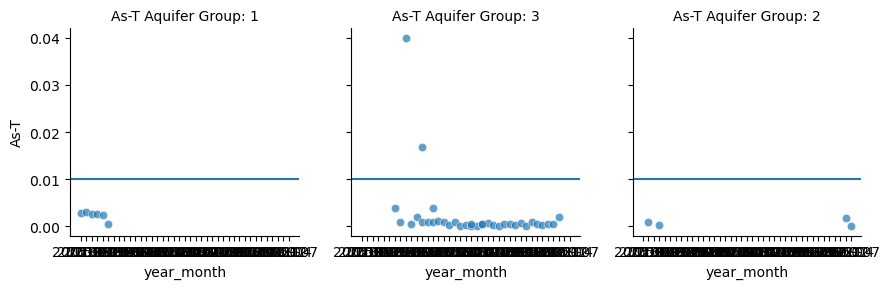

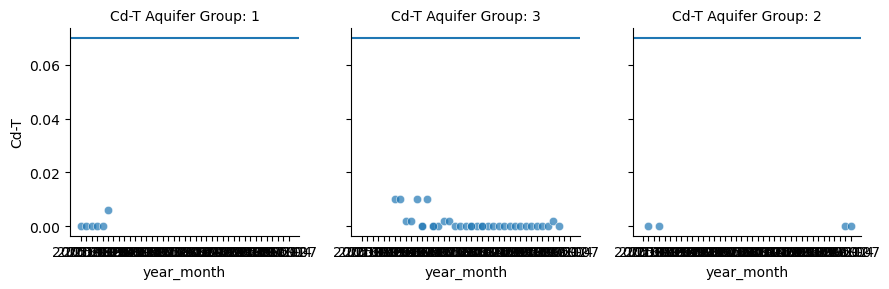

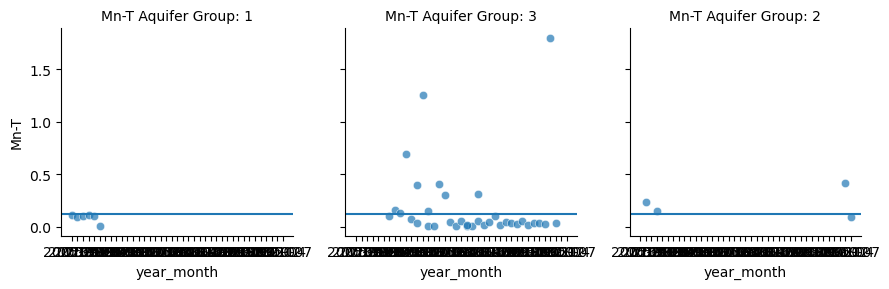

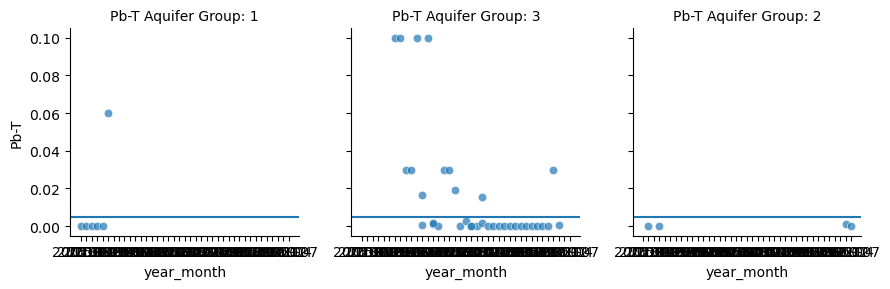

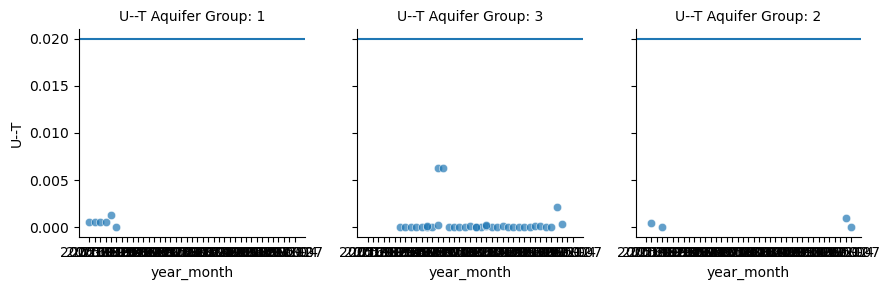

In [34]:
Total_Metals = df_SWIcltime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
#plt.savefig('Figures/metalsoverCADdrinkingwaterSWIsc.png')

Datat.columns


#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols = ['pH']
cleaned_dataset_array = replace_outliers_with_iqr(Datat[numeric_cols], 1.5)


In [35]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID df_SWIcl style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH','Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP',]
cleaned_dataset_array1 = replace_outliers_with_iqr(df_SWIcl[numeric_cols1], 1.5)
df_SWIcl[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        high_outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[high_outliers, col] = upper_threshold
        # Update col_values after replacing high outliers
        col_values = cleaned_dataset[col].values
        low_outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[low_outliers, col] = lower_threshold
    return cleaned_dataset
'''
# Assume df_SWIcl is your DataFrame
numeric_cols = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']

# Call your function on just the numeric columns
cleaned_dataset_array = replace_outliers_with_threshold(df_SWIcl[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=df_SWIcl.index)

df_SWIcl[numeric_cols] = cleaned_dataset
'''

df_SWIclpastremoval1 = df_SWIcl.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_46720\863099821.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWIcl[numeric_cols1] = cleaned_dataset_array1


In [36]:
from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
# Apply the transformation to the specified columns
df_SWIcl[cols_to_transform] = pt.fit_transform(df_SWIcl[cols_to_transform])

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_46720\2584074304.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWIcl[cols_to_transform] = pt.fit_transform(df_SWIcl[cols_to_transform])


In [37]:
df_SWIcl.shape

(45, 24)

In [38]:
#df_SWIcl.to_csv('df_SWIcl.csv')

In [39]:
df_SWIcl.shape

(45, 24)

In [40]:
df_SWIcl.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [41]:
# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

# assuming `df` is your DataFrame
selected_columns = df_SWIcl.iloc[:, :23]  # select the first 26 columns
group_column = df_SWIcl.iloc[:, 23]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = df_SWIcl.iloc[:, 23].unique()

# calculate summary statistics and percentiles for each group
all_summaries3 = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries3.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df3 = pd.concat(all_summaries3)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df3.to_csv('Stats/statssummarySWIcl.csv')

# check the DataFrame
print(summary_df3)

                    Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
1 mean                          0.456422  1.110010  1.178031 -0.510927   
  var                           0.935493  0.687402  0.066191  0.995383   
  std                           0.967209  0.829097  0.257276  0.997689   
  min                          -1.516734 -0.576846  0.660469 -0.970279   
  max                           0.899890  1.531446  1.365087  1.521296   
  skew                         -2.443070 -2.413922 -2.283733  2.426442   
  median                        0.843870  1.434184  1.256026 -0.904145   
  kurt                          5.975531  5.862402  5.445582  5.911007   
  10.0% percentile             -0.357533  0.380037  0.953536 -0.970279   
  50.0% percentile              0.843870  1.434184  1.256026 -0.904145   
  90.0% percentile              0.882927  1.515808  1.324532  0.341643   
  cv                            2.119112  0.746928  0.218394 -1.952702   
3 mean                         -0.0978

In [42]:
correlation_matSWIcl = df_SWIcl.corr()
correlation_matSWIcl.to_csv('Stats/correlation_matafterSWIcl.csv')
print(correlation_matSWIcl)


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.212681 -0.191151 -0.153779   
As-T                                 0.212681  1.000000  0.436019  0.293448   
Ca-T                                -0.191151  0.436019  1.000000  0.283418   
Cd-T                                -0.153779  0.293448  0.283418  1.000000   
Chlrid:D                            -0.292001 -0.160057 -0.176602  0.205522   
Fe-T                                 0.208187  0.439227  0.224016  0.319131   
Mn-T                                -0.196960  0.242038  0.398877  0.490509   
N.Kjel:T                             0.152306 -0.375366 -0.262544 -0.141940   
P--T                                 0.159905  0.014054  0.153245  0.037026   
Pb-T                                -0.137187  0.193423  0.153288  0.872714   
Residue Filterable 1.0u              0.042959  0.042753 -0.048759  0.192137   
Specific Conductance                 0.010243  0.017

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_46720\1467720164.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matSWIcl = df_SWIcl.corr()


In [43]:
correlation_tauSWIcl = df_SWIcl.corr(method='kendall')
print(correlation_tauSWIcl)
correlation_tauSWIcl.to_csv('Stats/correlation_tauSWIcl.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_46720\3028951905.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tauSWIcl = df_SWIcl.corr(method='kendall')


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.099157 -0.175367 -0.111216   
As-T                                 0.099157  1.000000  0.354013  0.251395   
Ca-T                                -0.175367  0.354013  1.000000  0.216064   
Cd-T                                -0.111216  0.251395  0.216064  1.000000   
Chlrid:D                            -0.178863 -0.138197 -0.140316  0.256687   
Fe-T                                 0.144605  0.342002  0.200715  0.226824   
Mn-T                                -0.105051  0.182822  0.257148  0.279347   
N.Kjel:T                             0.084827 -0.224260 -0.114523 -0.010892   
P--T                                 0.105594  0.029572  0.063594  0.101610   
Pb-T                                -0.112065  0.236241  0.082015  0.728754   
Residue Filterable 1.0u              0.068055  0.024067 -0.033537  0.228411   
Specific Conductance                 0.032487 -0.018

In [44]:
correlation_rhoSWIcl = df_SWIcl.corr(method='spearman')
correlation_rhoSWIcl.to_csv('Stats/correlation_rhoSWIcl.csv')
print(correlation_rhoSWIcl)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.153639 -0.190202 -0.133675   
As-T                                 0.153639  1.000000  0.464392  0.328032   
Ca-T                                -0.190202  0.464392  1.000000  0.270104   
Cd-T                                -0.133675  0.328032  0.270104  1.000000   
Chlrid:D                            -0.274980 -0.163825 -0.193198  0.352297   
Fe-T                                 0.217476  0.413971  0.241487  0.287155   
Mn-T                                -0.176577  0.284144  0.399057  0.398252   
N.Kjel:T                             0.124378 -0.330851 -0.195680 -0.025262   
P--T                                 0.121825  0.027917  0.100488  0.131979   
Pb-T                                -0.154155  0.313431  0.112937  0.855523   
Residue Filterable 1.0u              0.087263  0.041237 -0.097947  0.296682   
Specific Conductance                 0.029790 -0.015

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_46720\3226147589.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rhoSWIcl = df_SWIcl.corr(method='spearman')


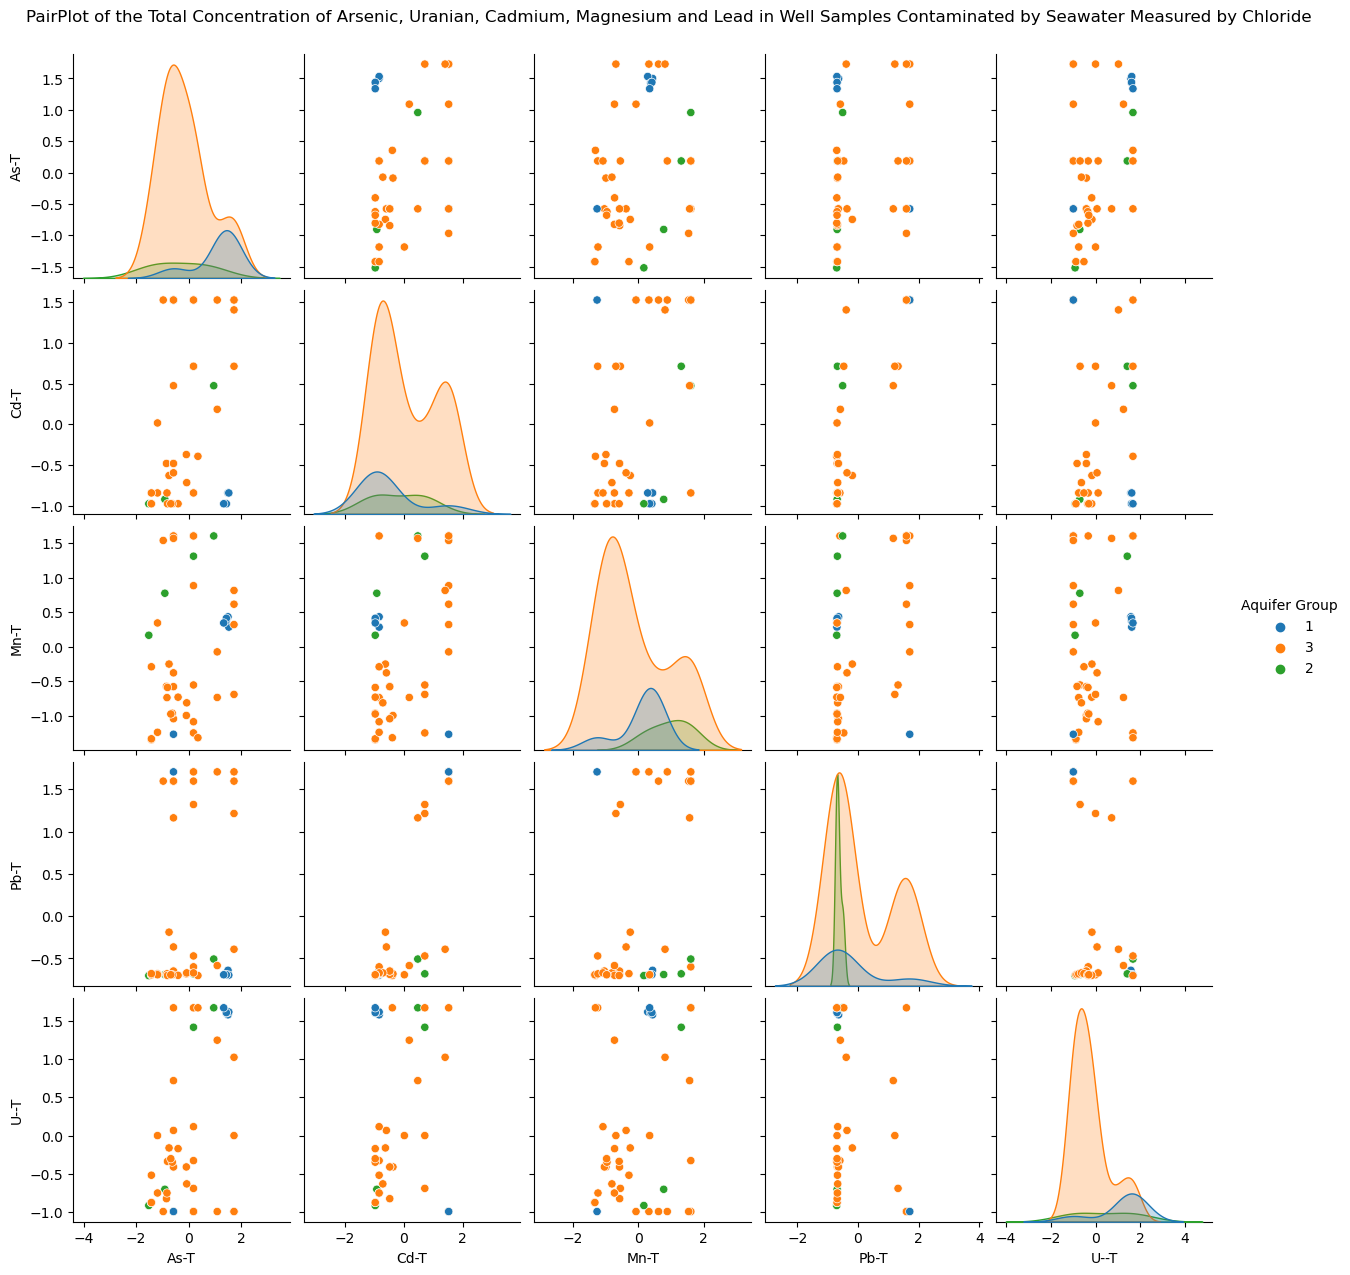

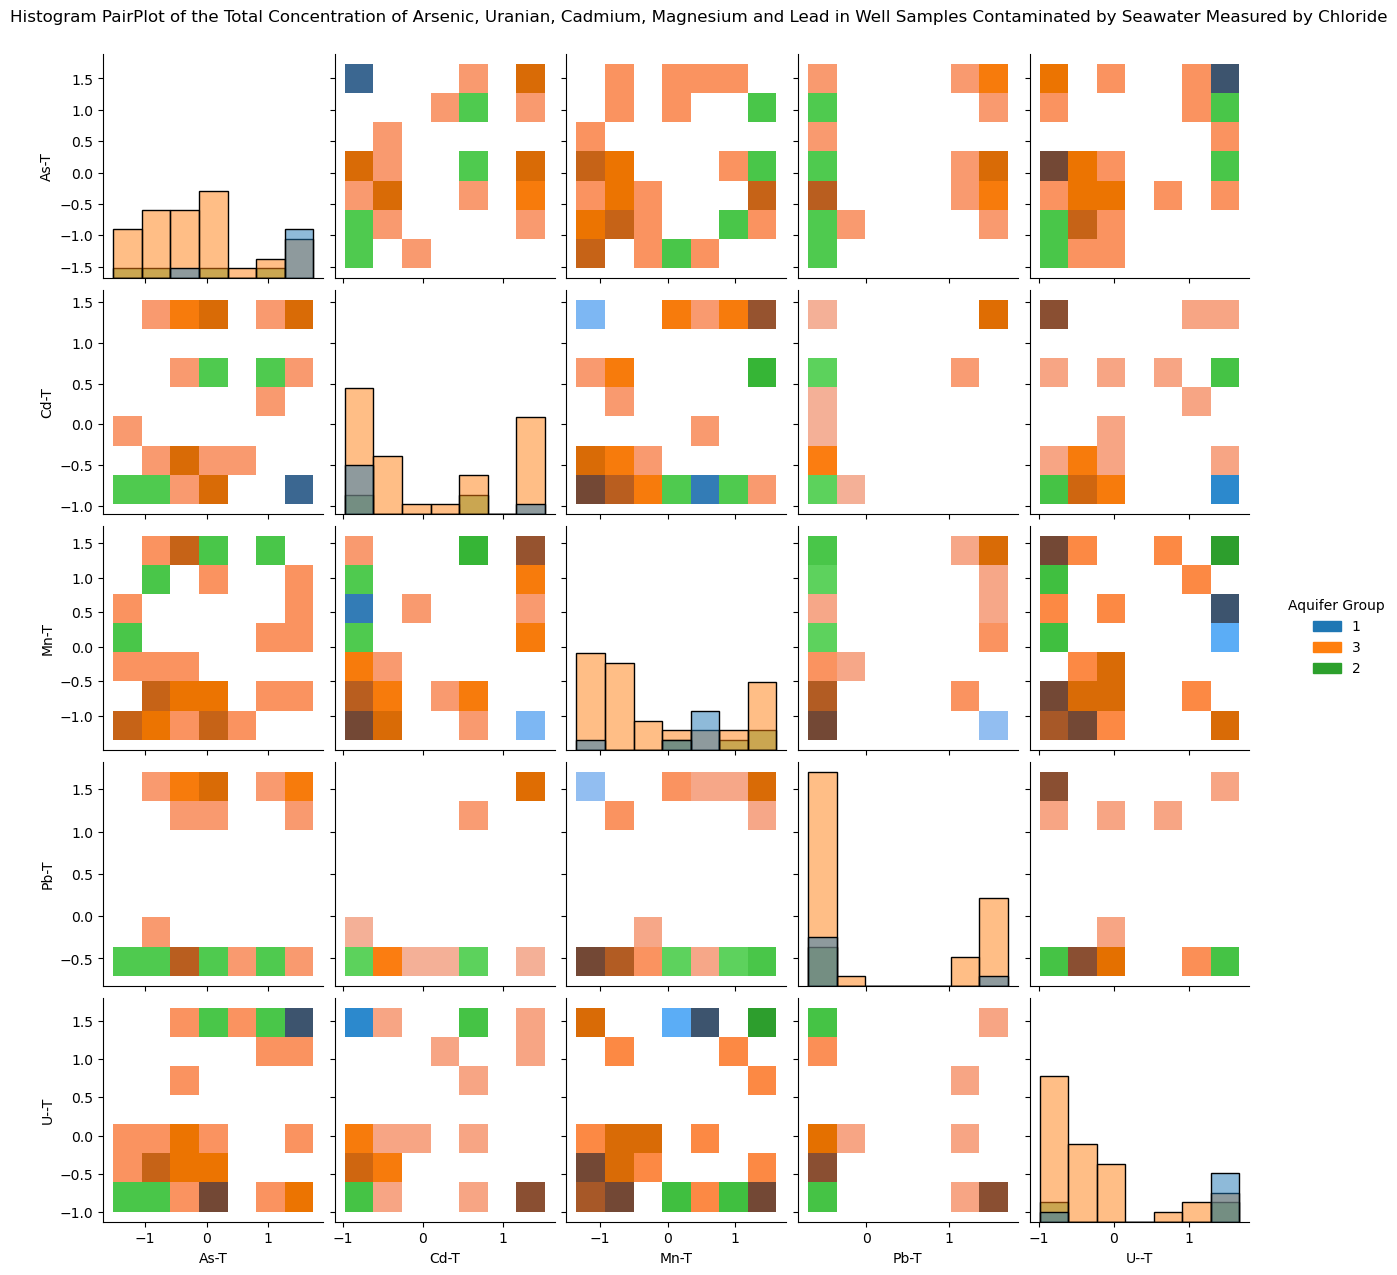

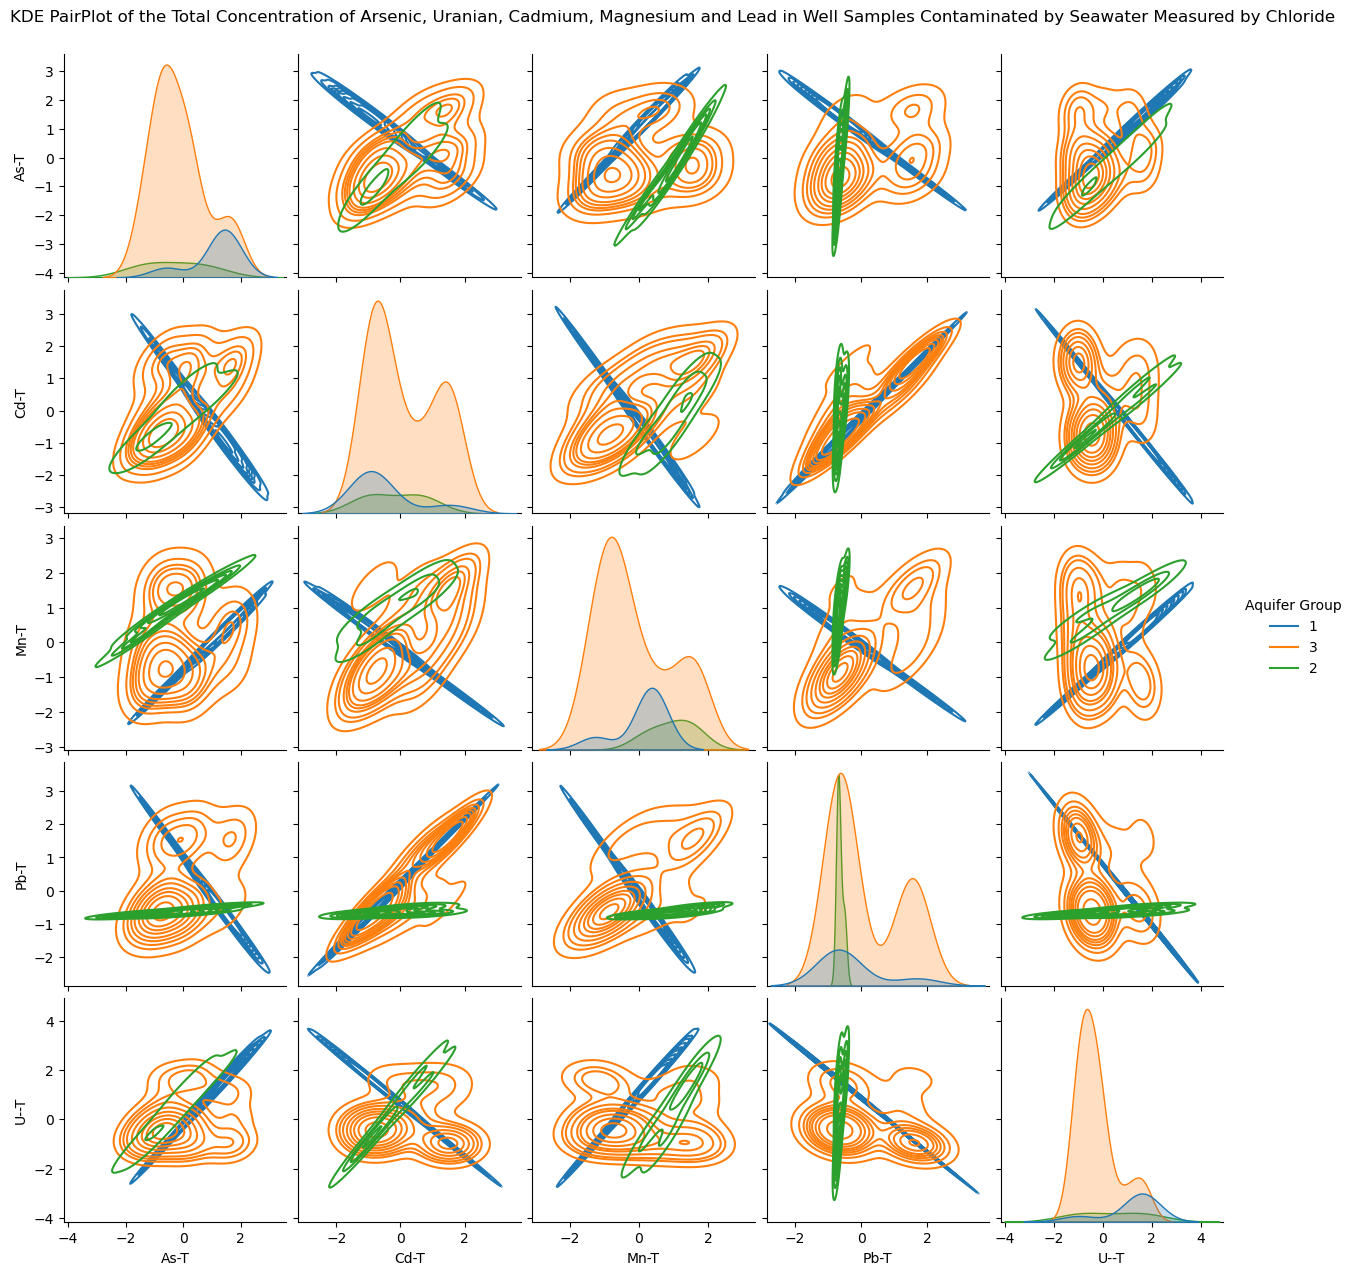

In [45]:
Metals_Total = df_SWIcl[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group']]
Metalsg = sns.pairplot(Metals_Total, hue="Aquifer Group")
Metalsg.fig.suptitle("PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/pairplotmetalsSWIcl.png') # Save the first figure

Metalsh = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="hist")
Metalsh.fig.suptitle("Histogram PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/histplotmetalsSWIcl.png') 

Metalsf = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="kde")
Metalsf.fig.suptitle("KDE PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/KDEplotmetalsSWIcl.png') 


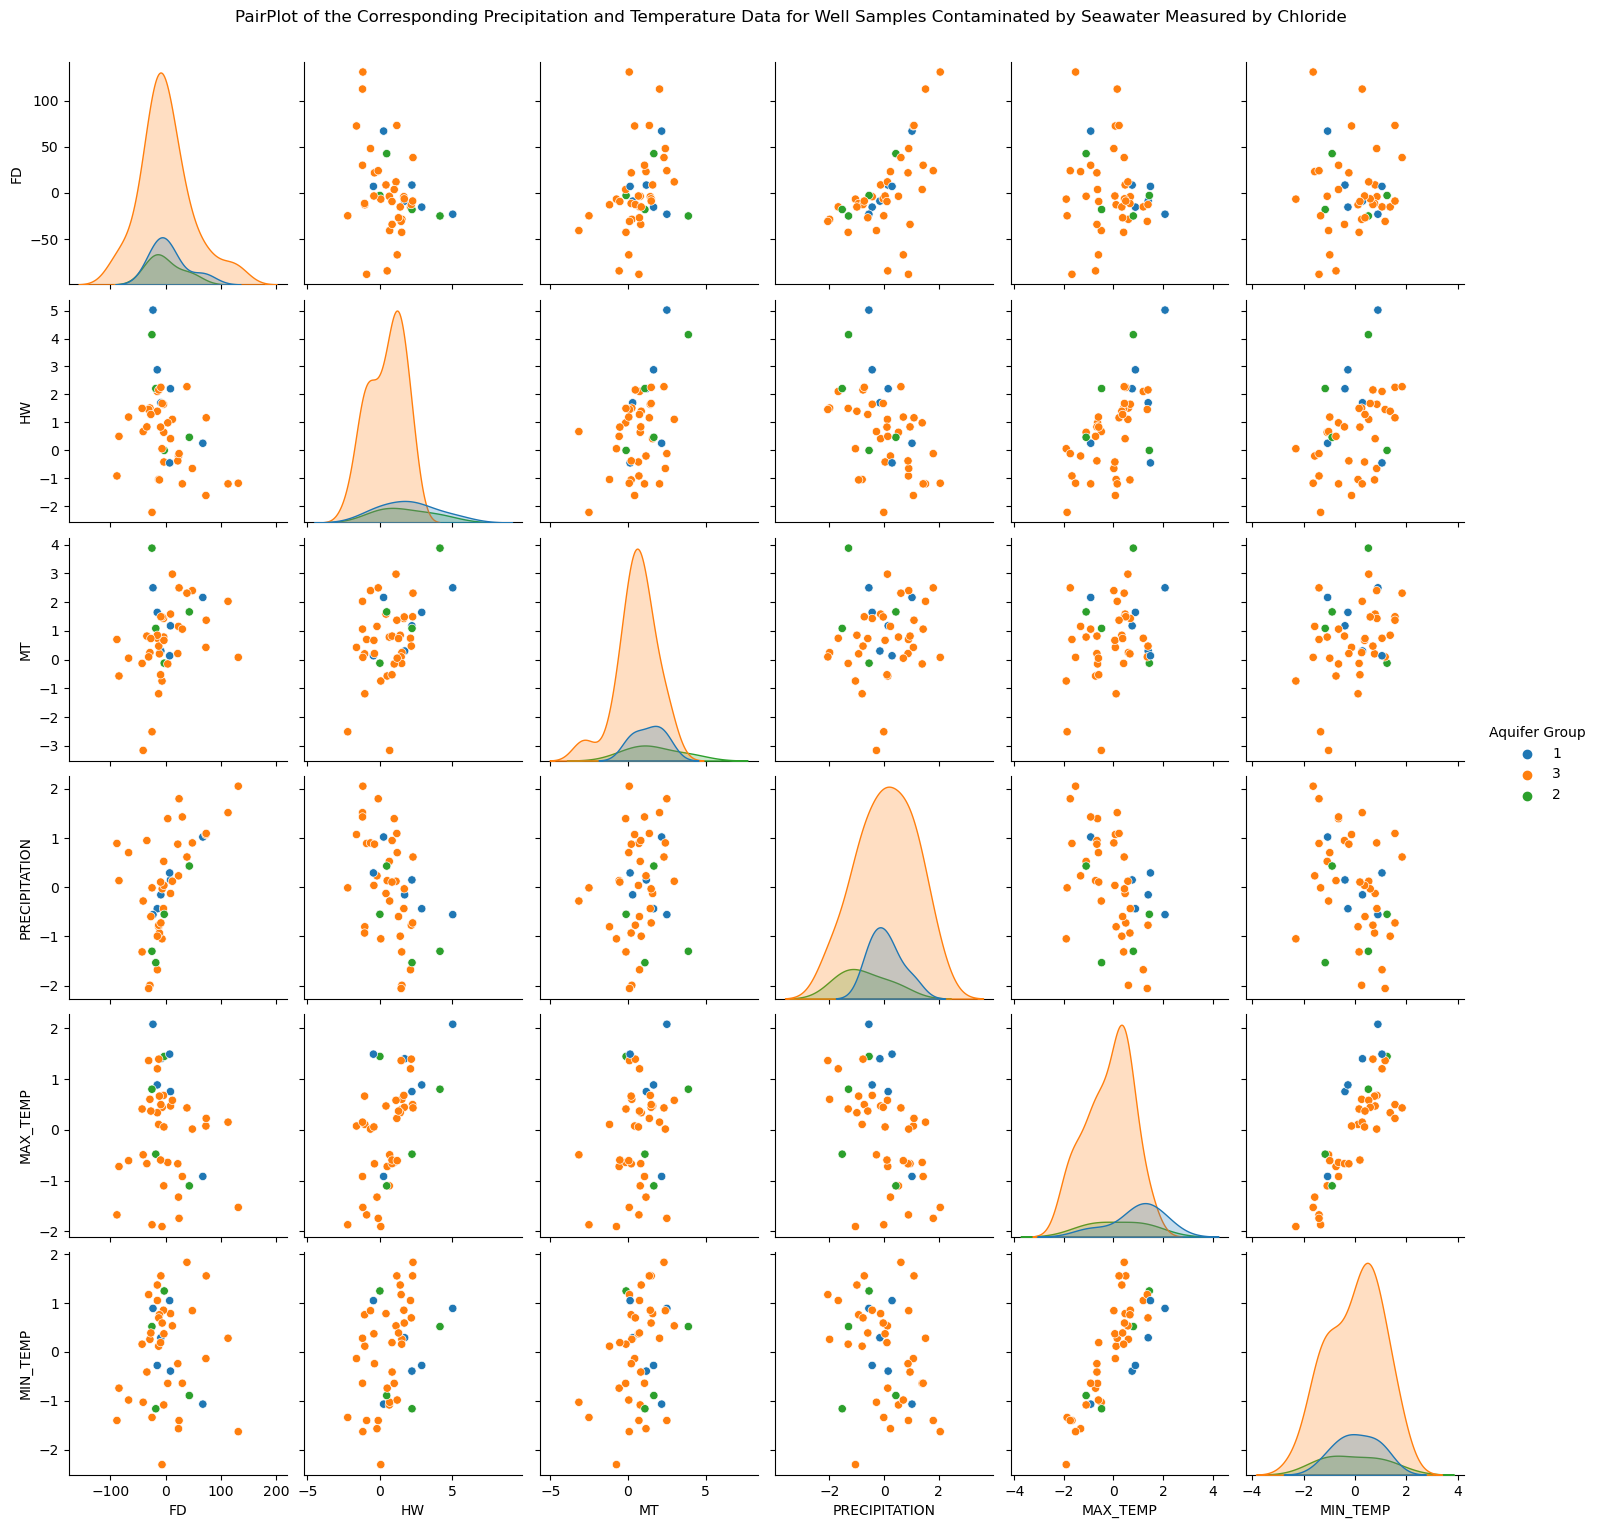

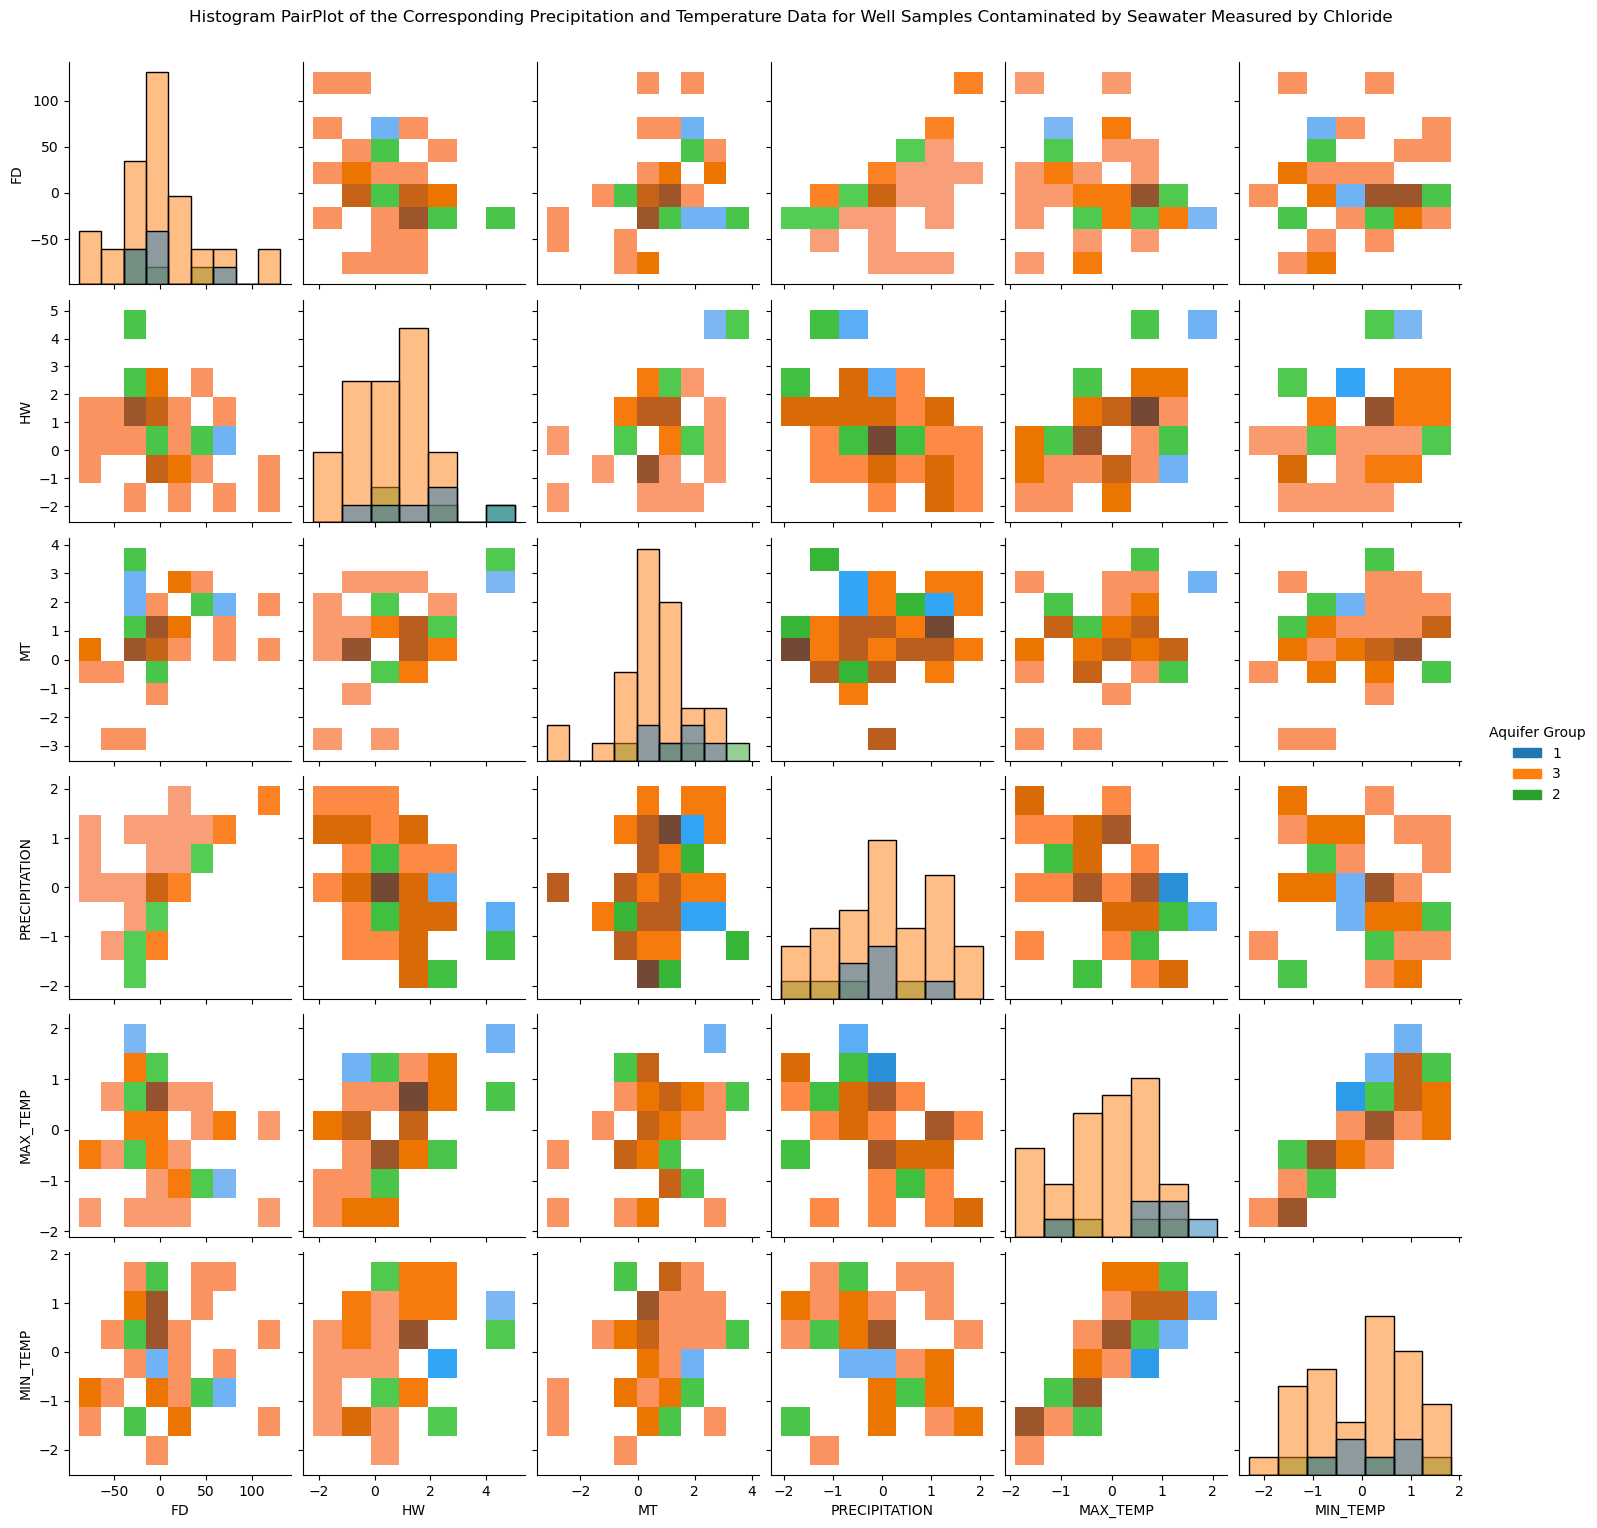

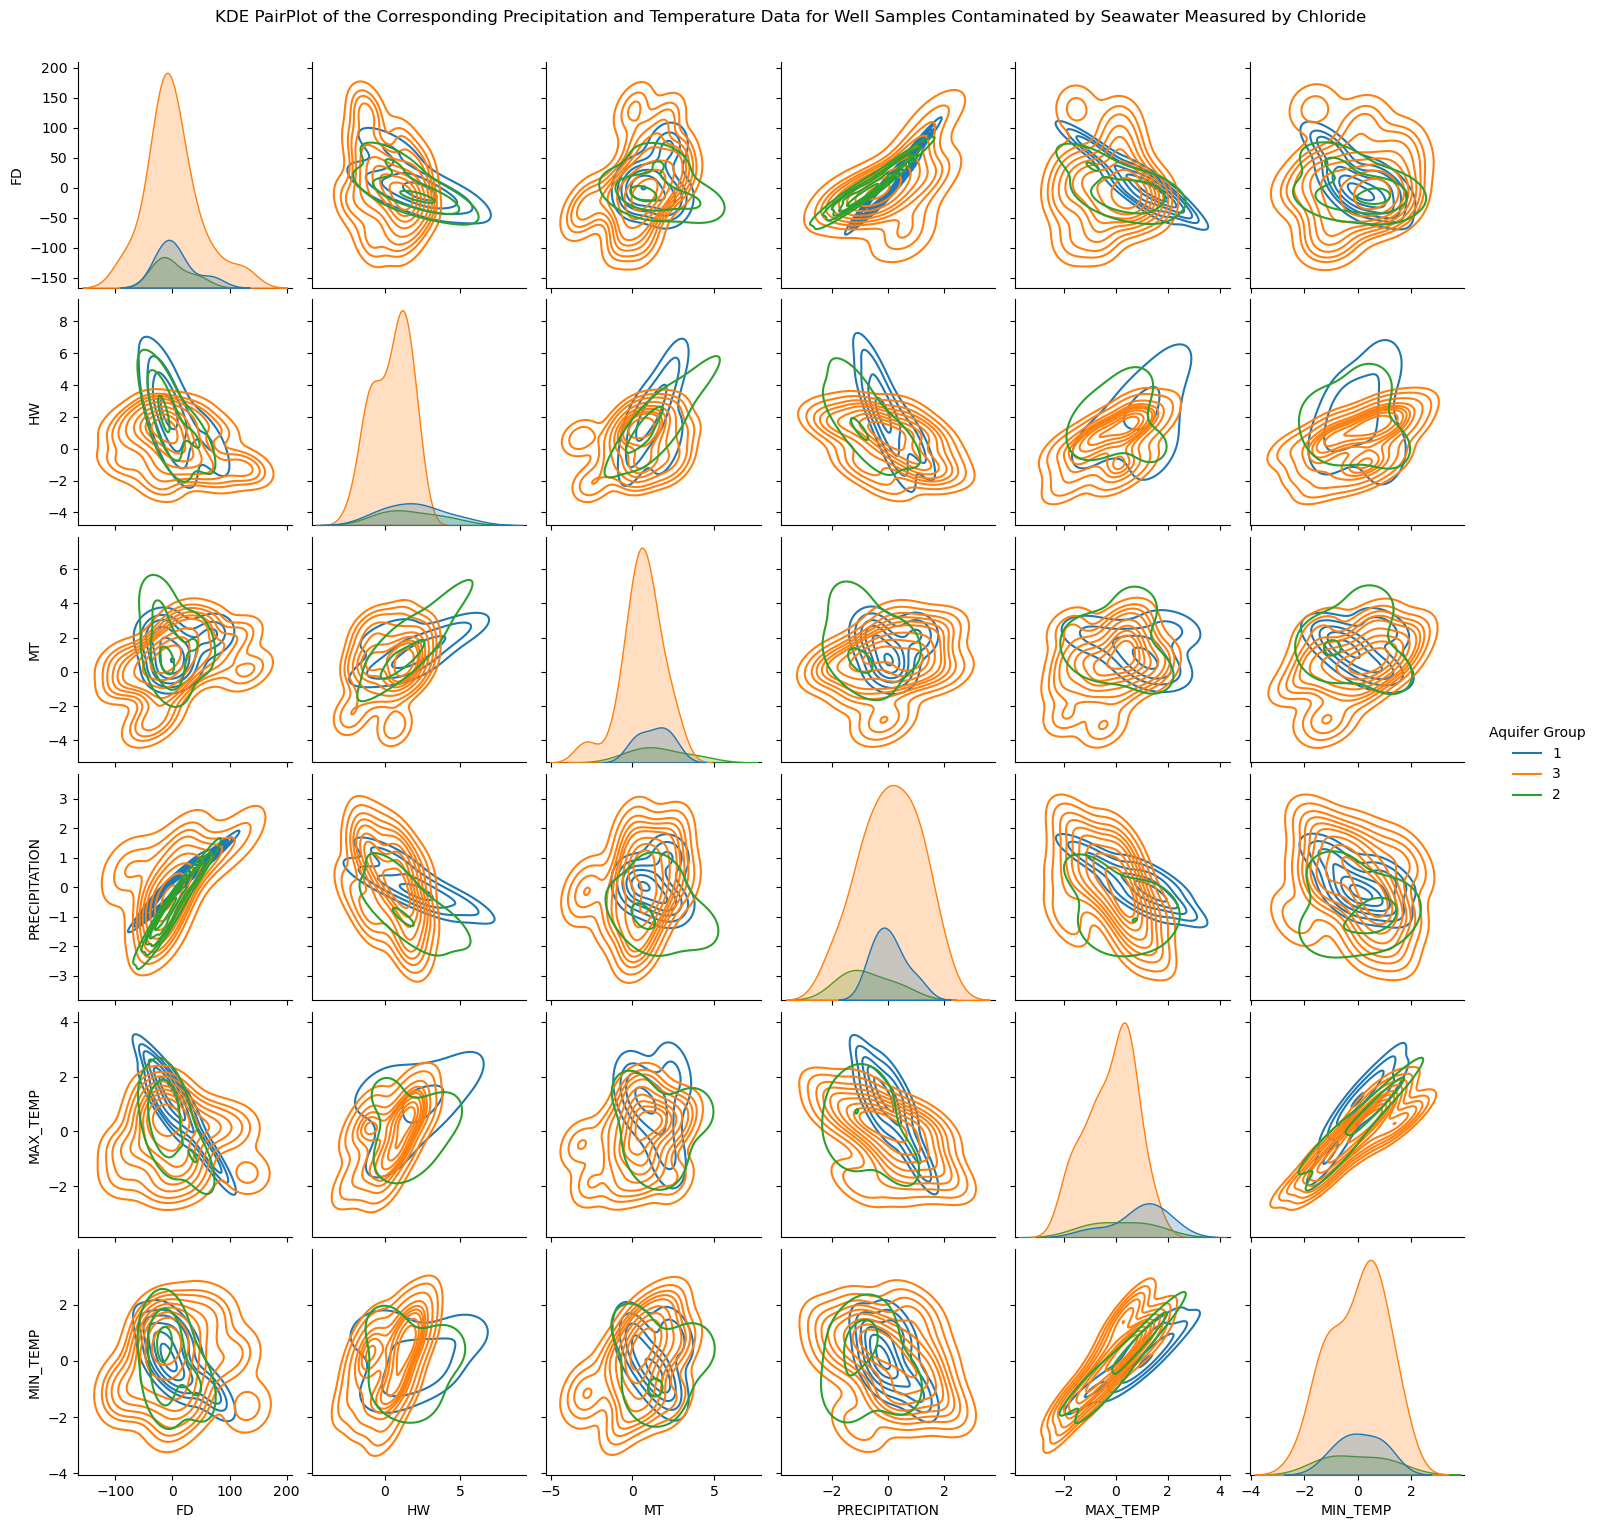

In [46]:
Precept = df_SWIcl[['FD', 'HW', 'MT', 'Aquifer Group', 'PRECIPITATION', 'MAX_TEMP', 'MIN_TEMP']]
Preceptg= sns.pairplot(Precept, hue="Aquifer Group")
Preceptg.fig.suptitle("PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/pairplotPreceptSWIcl.png') # Save the first figure

Precepth = sns.pairplot(Precept, hue="Aquifer Group", kind="hist")
Precepth.fig.suptitle("Histogram PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/histplotPreceptSWIcl.png') 

Preceptf = sns.pairplot(Precept, hue="Aquifer Group", kind="kde")
Preceptf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/KDEplotPreceptSWIcl.png') 

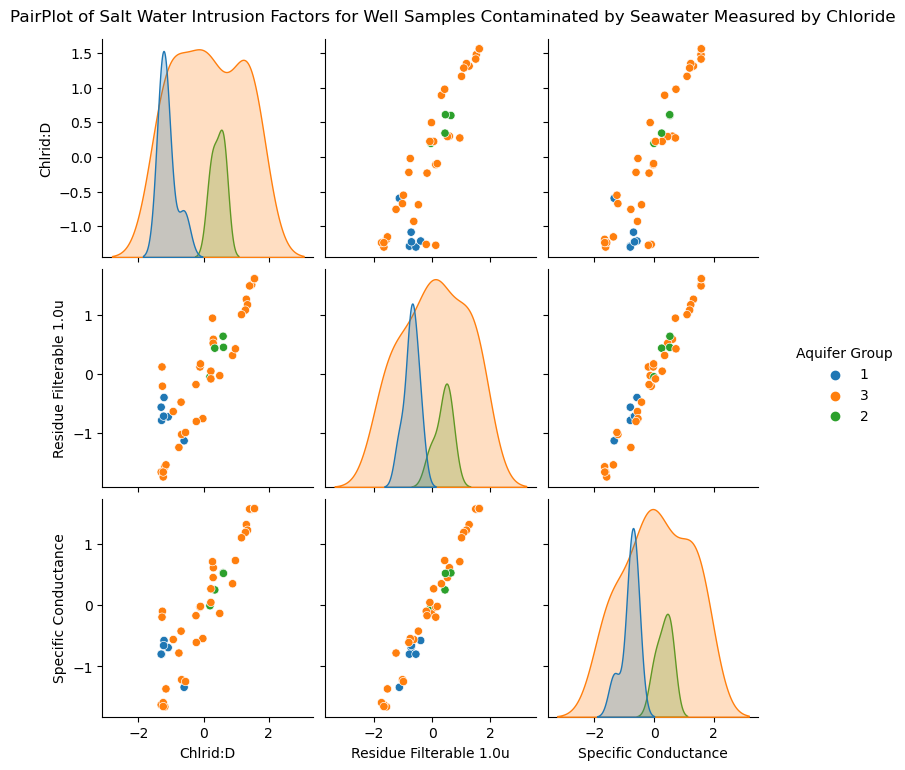

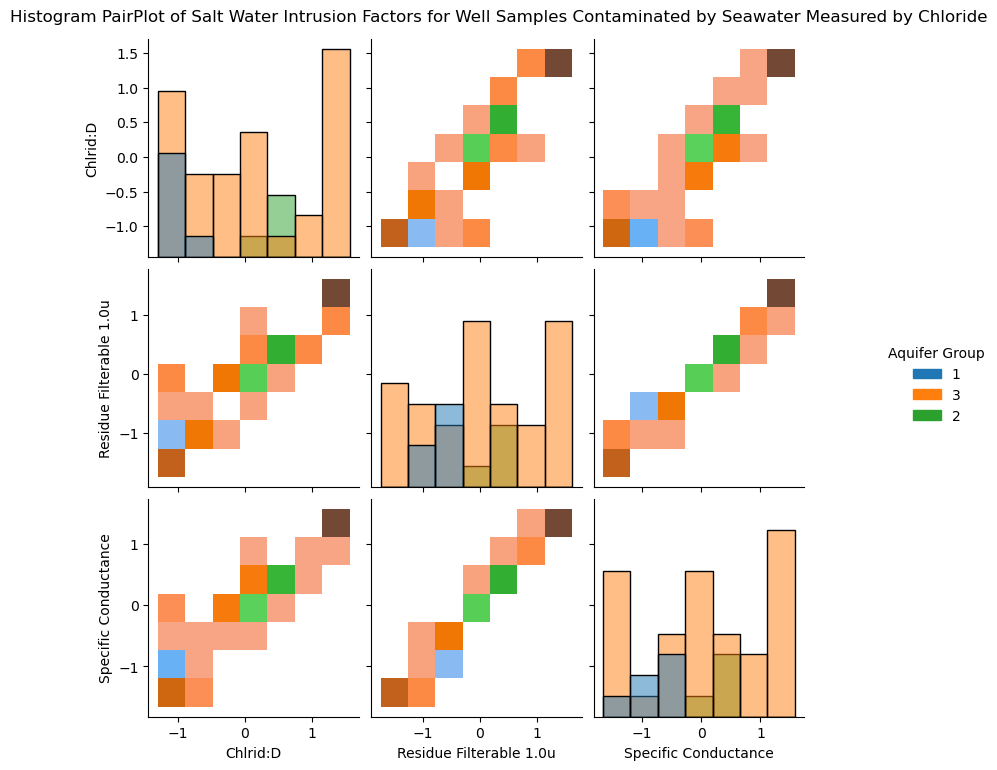

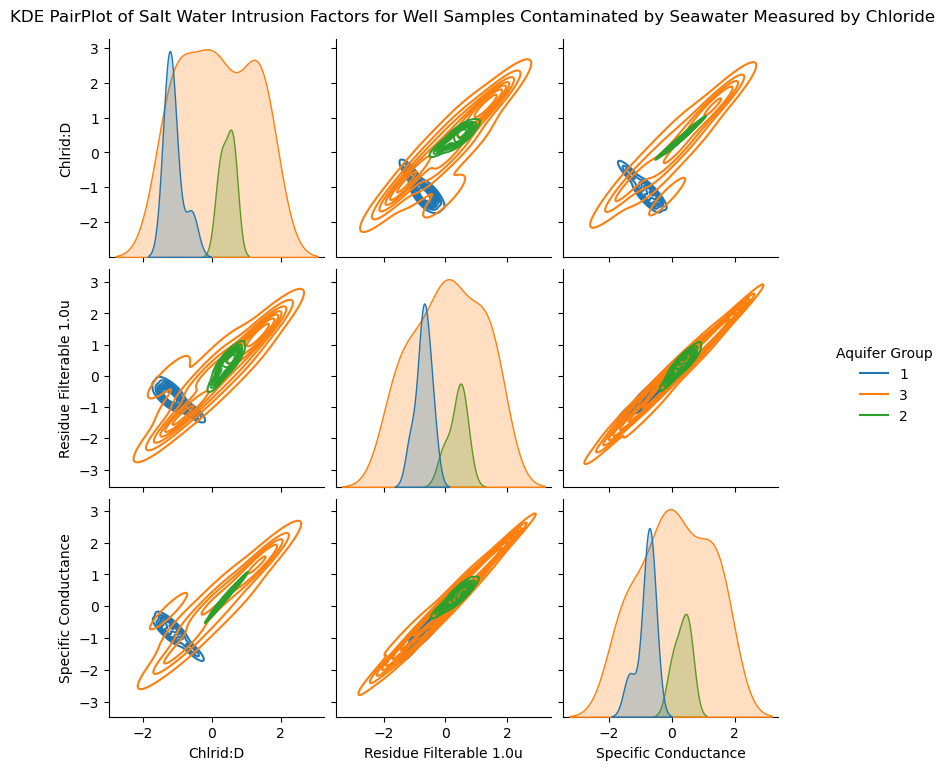

In [47]:
SWID = df_SWIcl[['Chlrid:D', 'Residue Filterable 1.0u', 'Specific Conductance', 'Aquifer Group']]
SWIDg= sns.pairplot(SWID, hue="Aquifer Group")
SWIDg.fig.suptitle("PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/pairplotSWIDSWIcl.png') # Save the first figure

SWIDh = sns.pairplot(SWID, hue="Aquifer Group", kind="hist")
SWIDh.fig.suptitle("Histogram PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/histplotSWIDSWIcl.png') 

SWIDf = sns.pairplot(SWID, hue="Aquifer Group", kind="kde")
SWIDf.fig.suptitle("KDE PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/KDEplotSWIDSWIcl.png') 

In [50]:
OthersD = df_SWIcl[['Alkalinity Total 4.5', 'Ca-T', 'Fe-T',
       'N.Kjel:T', 'P--T', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T', 'Aquifer Group']]

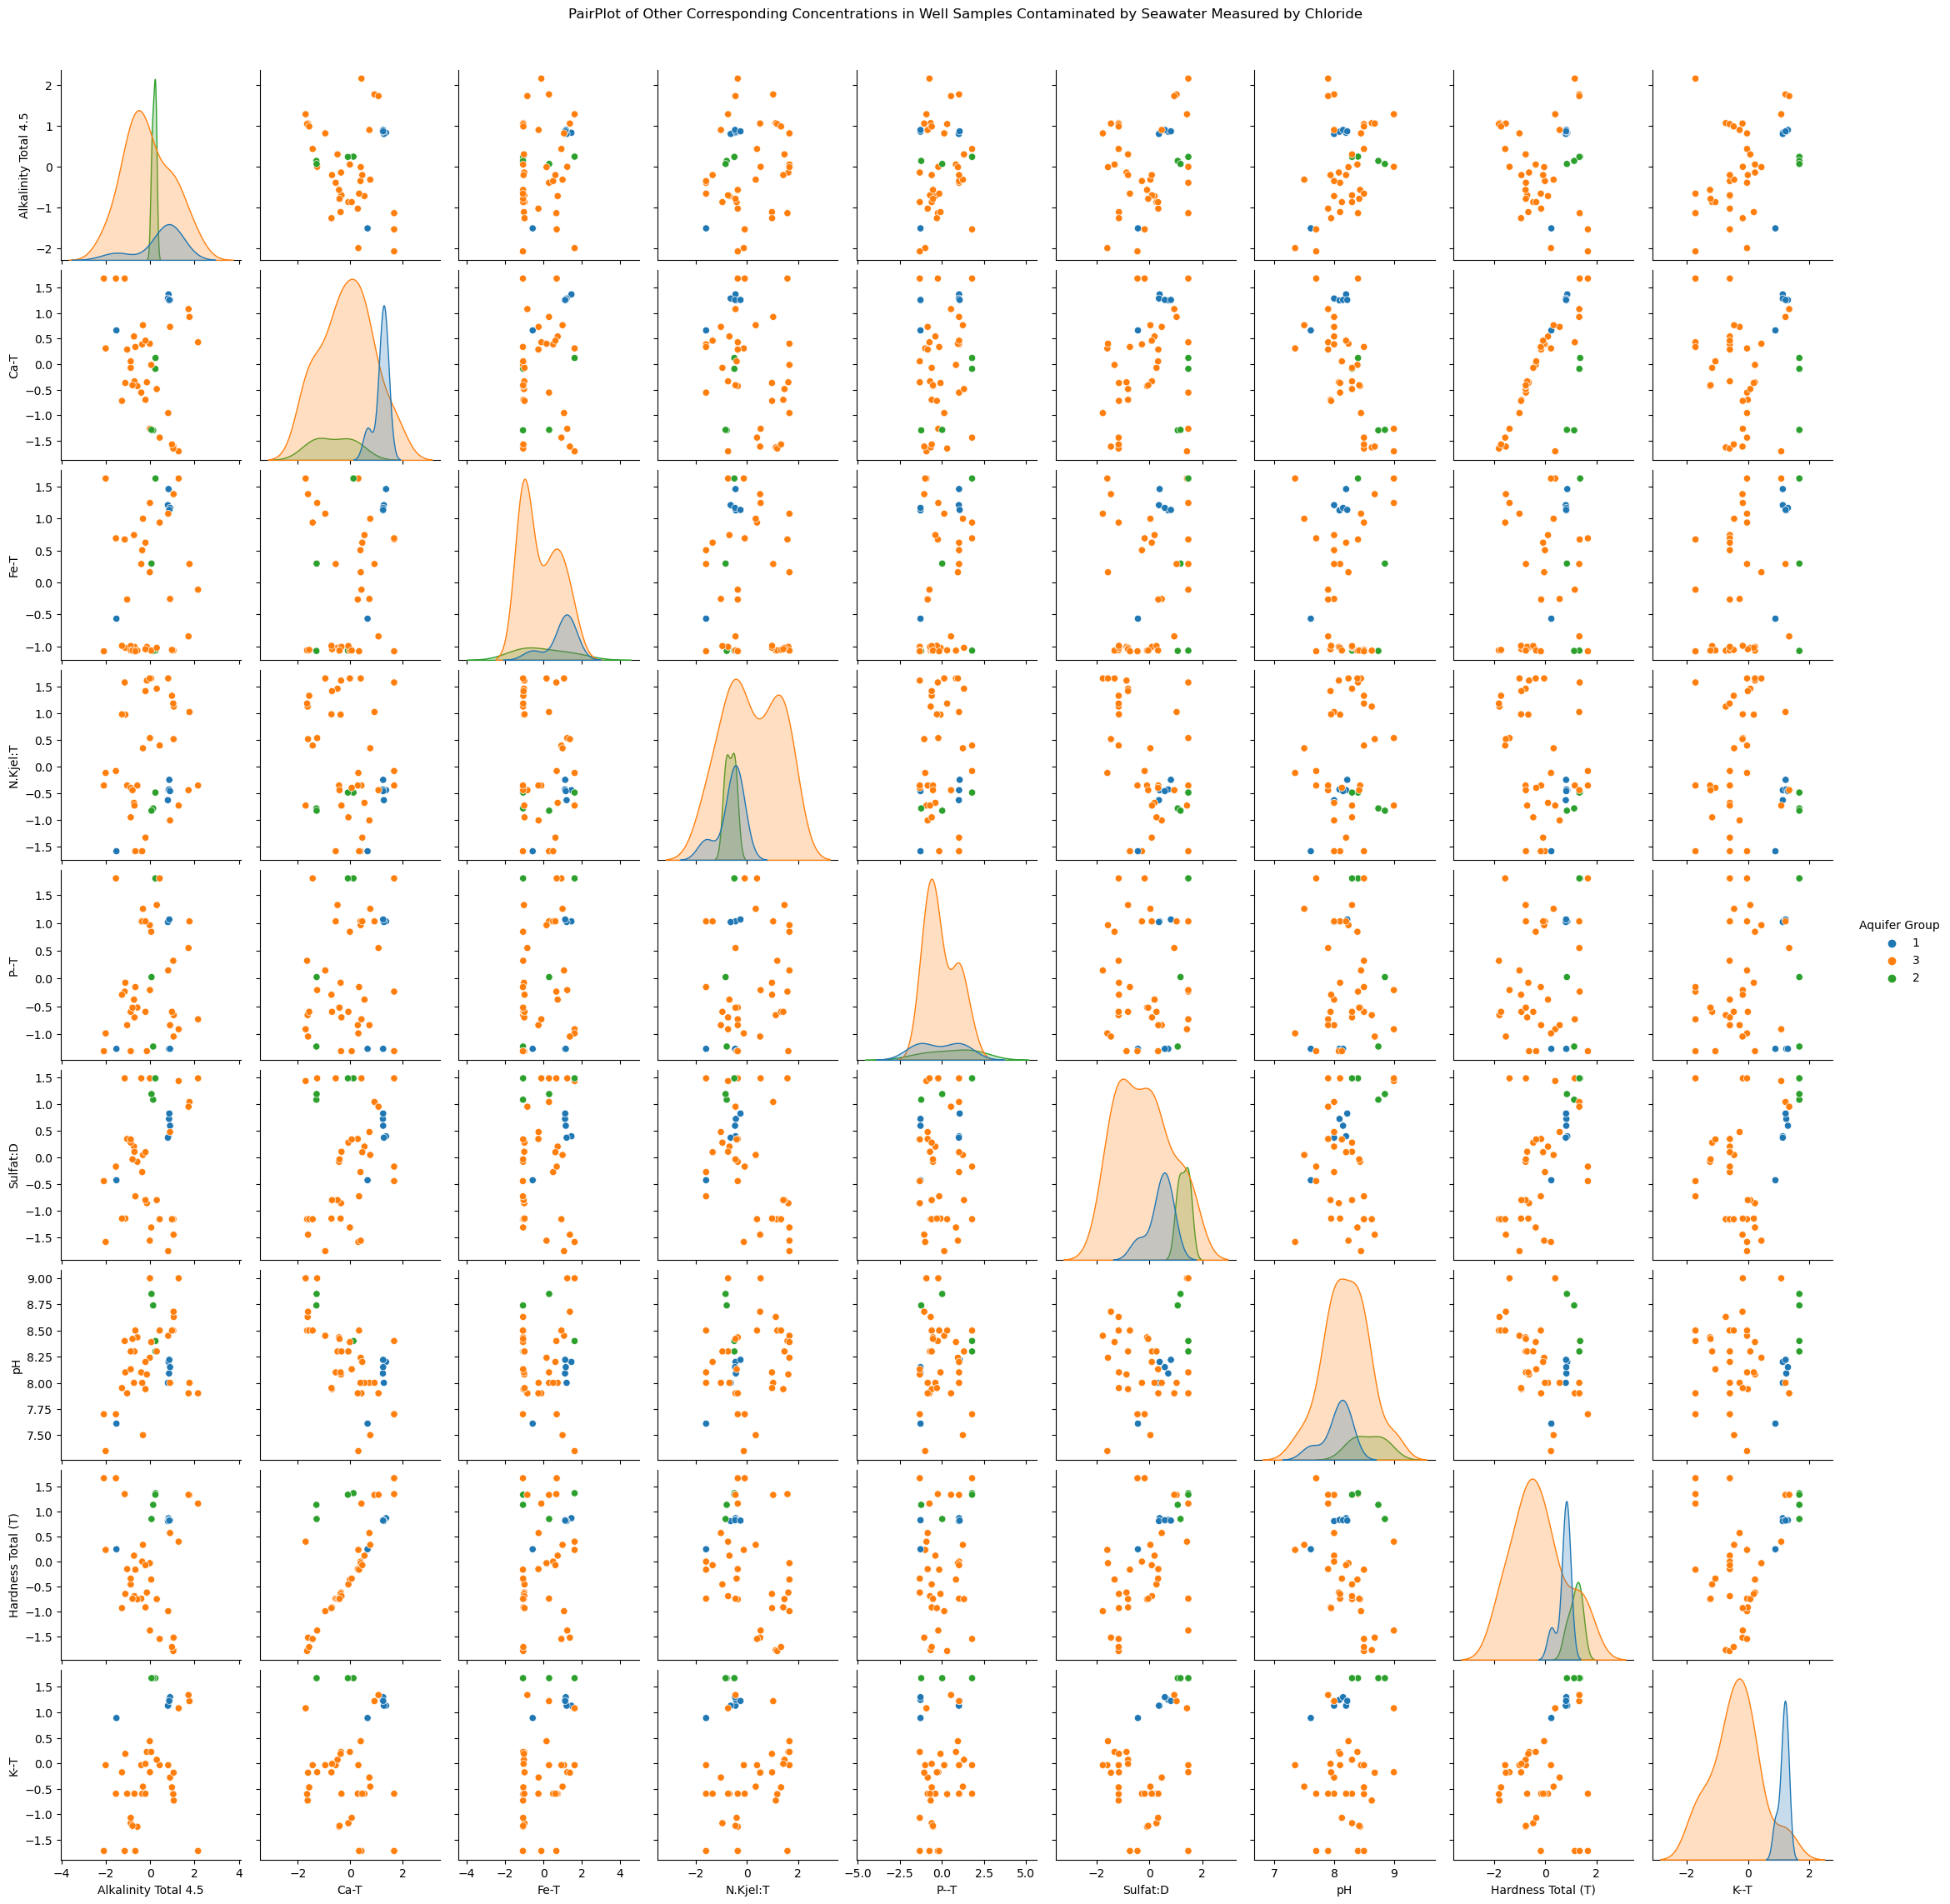

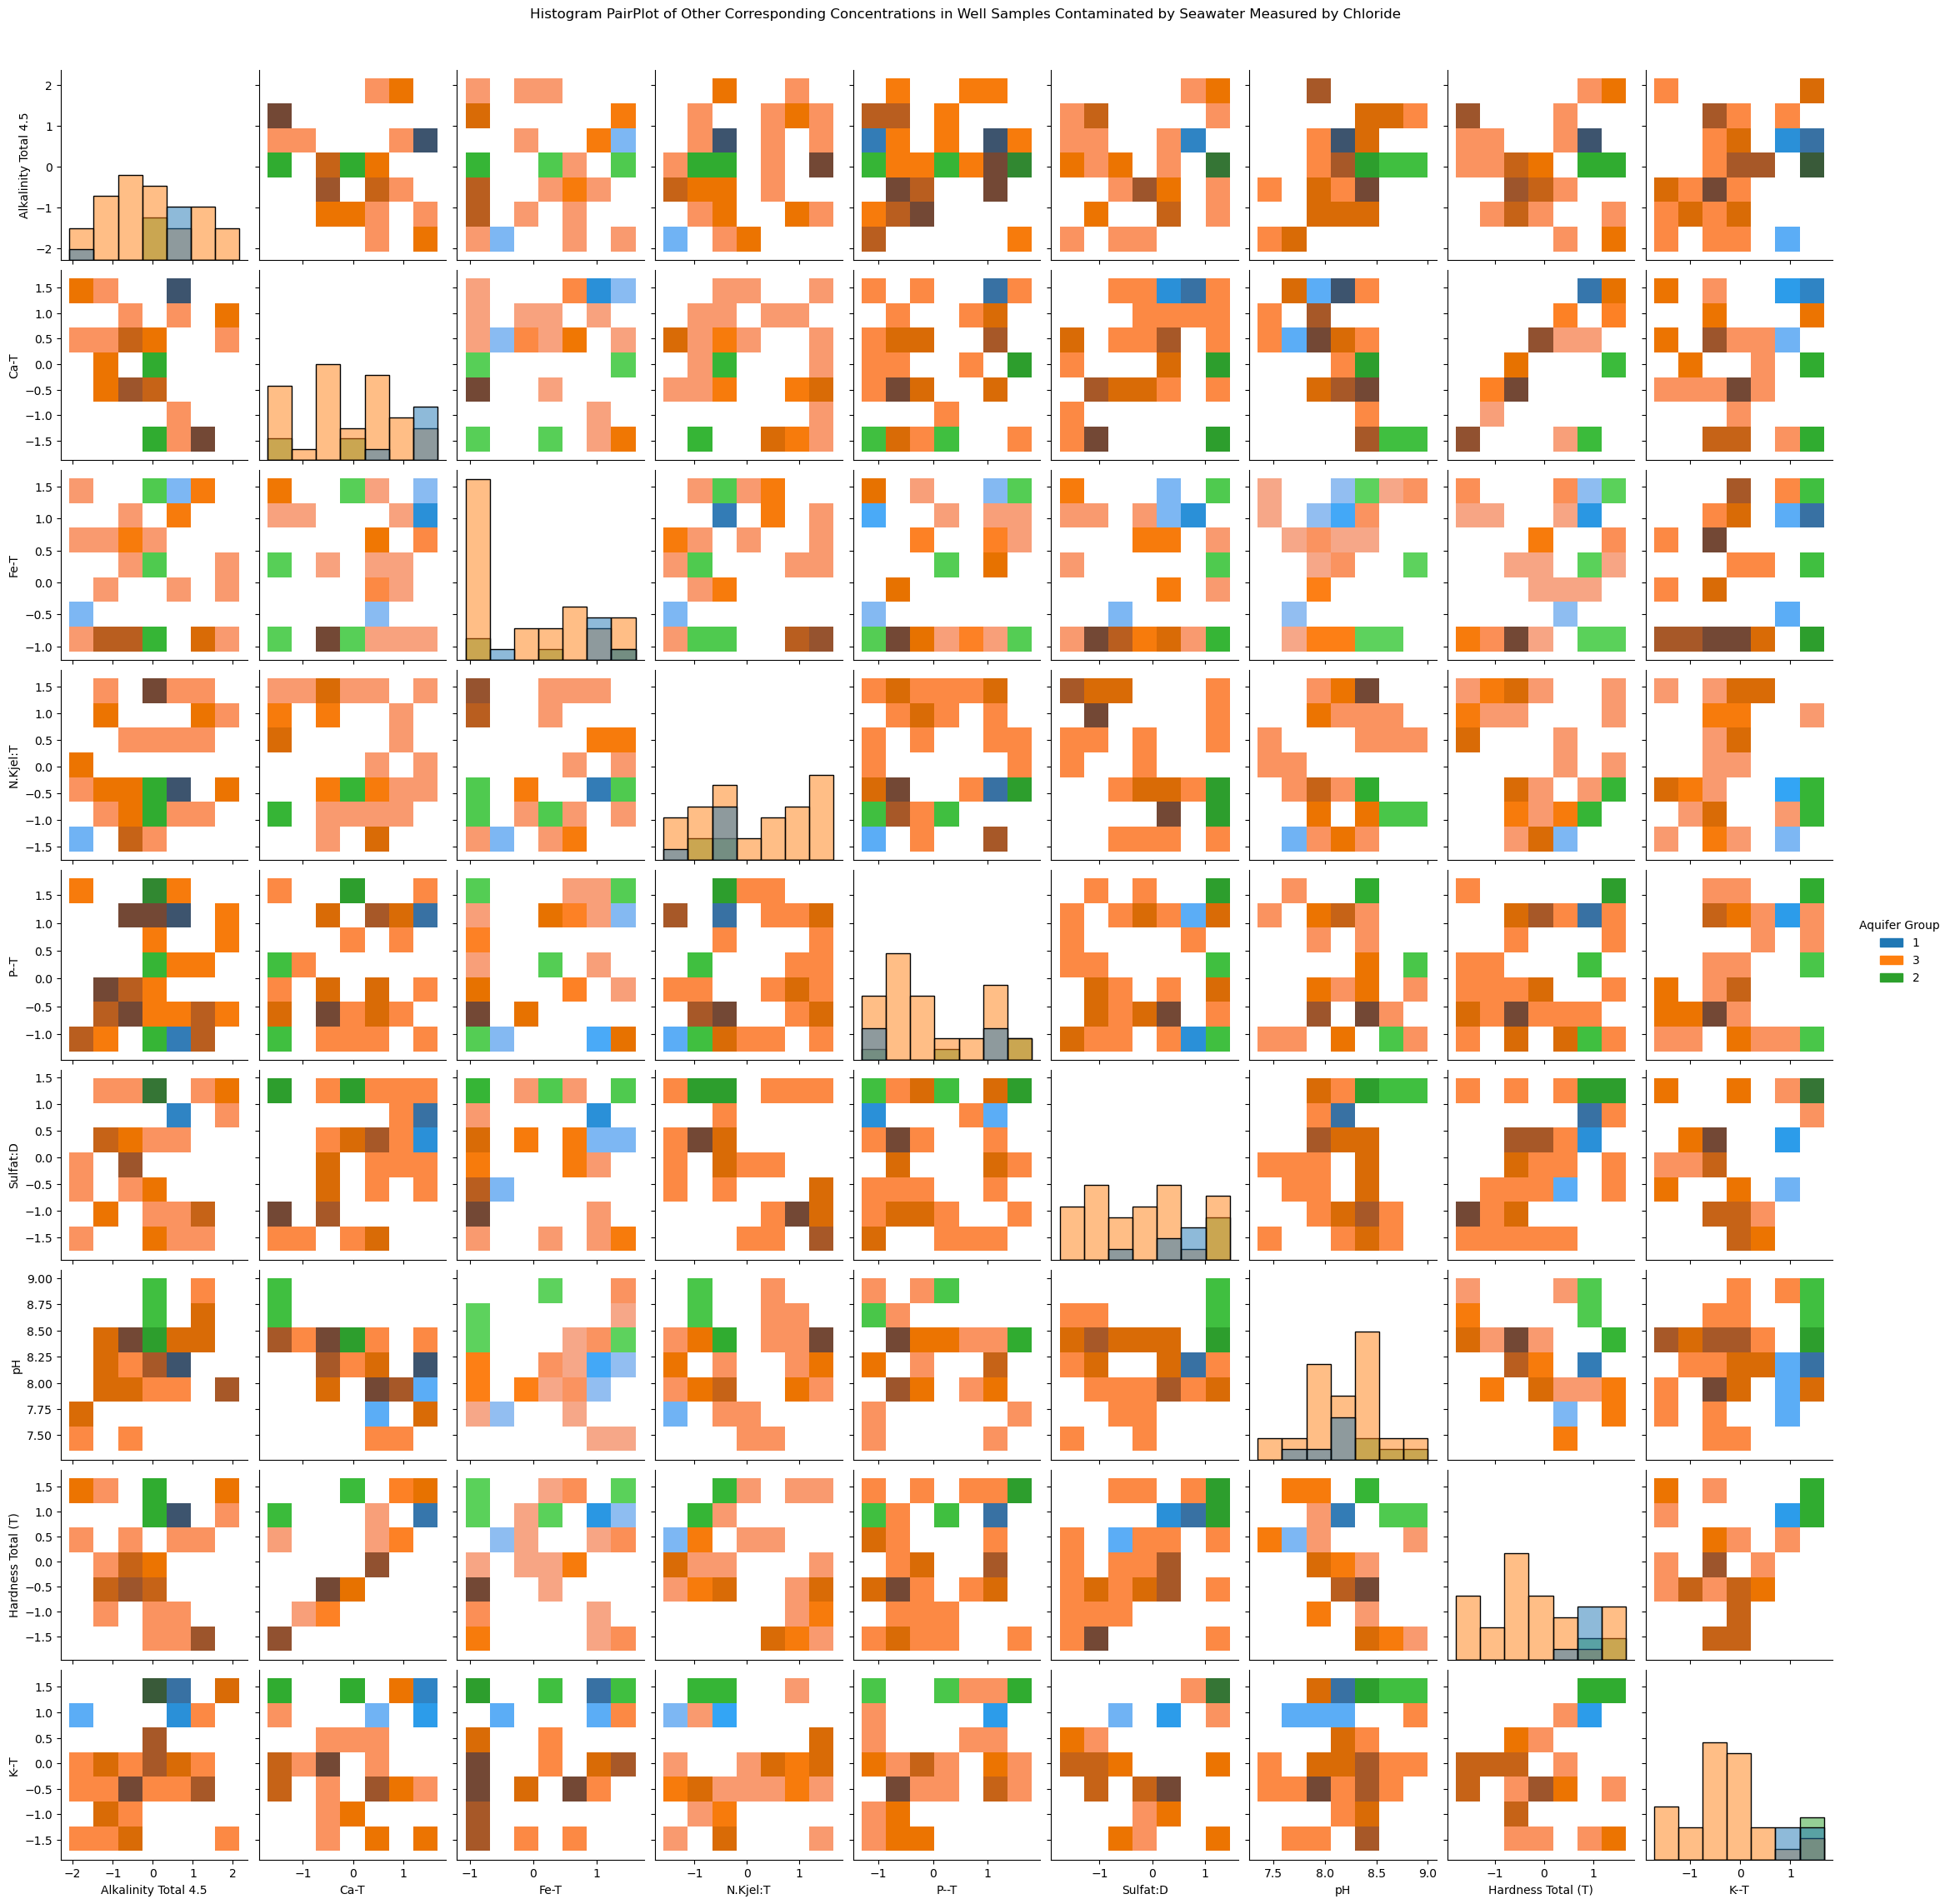

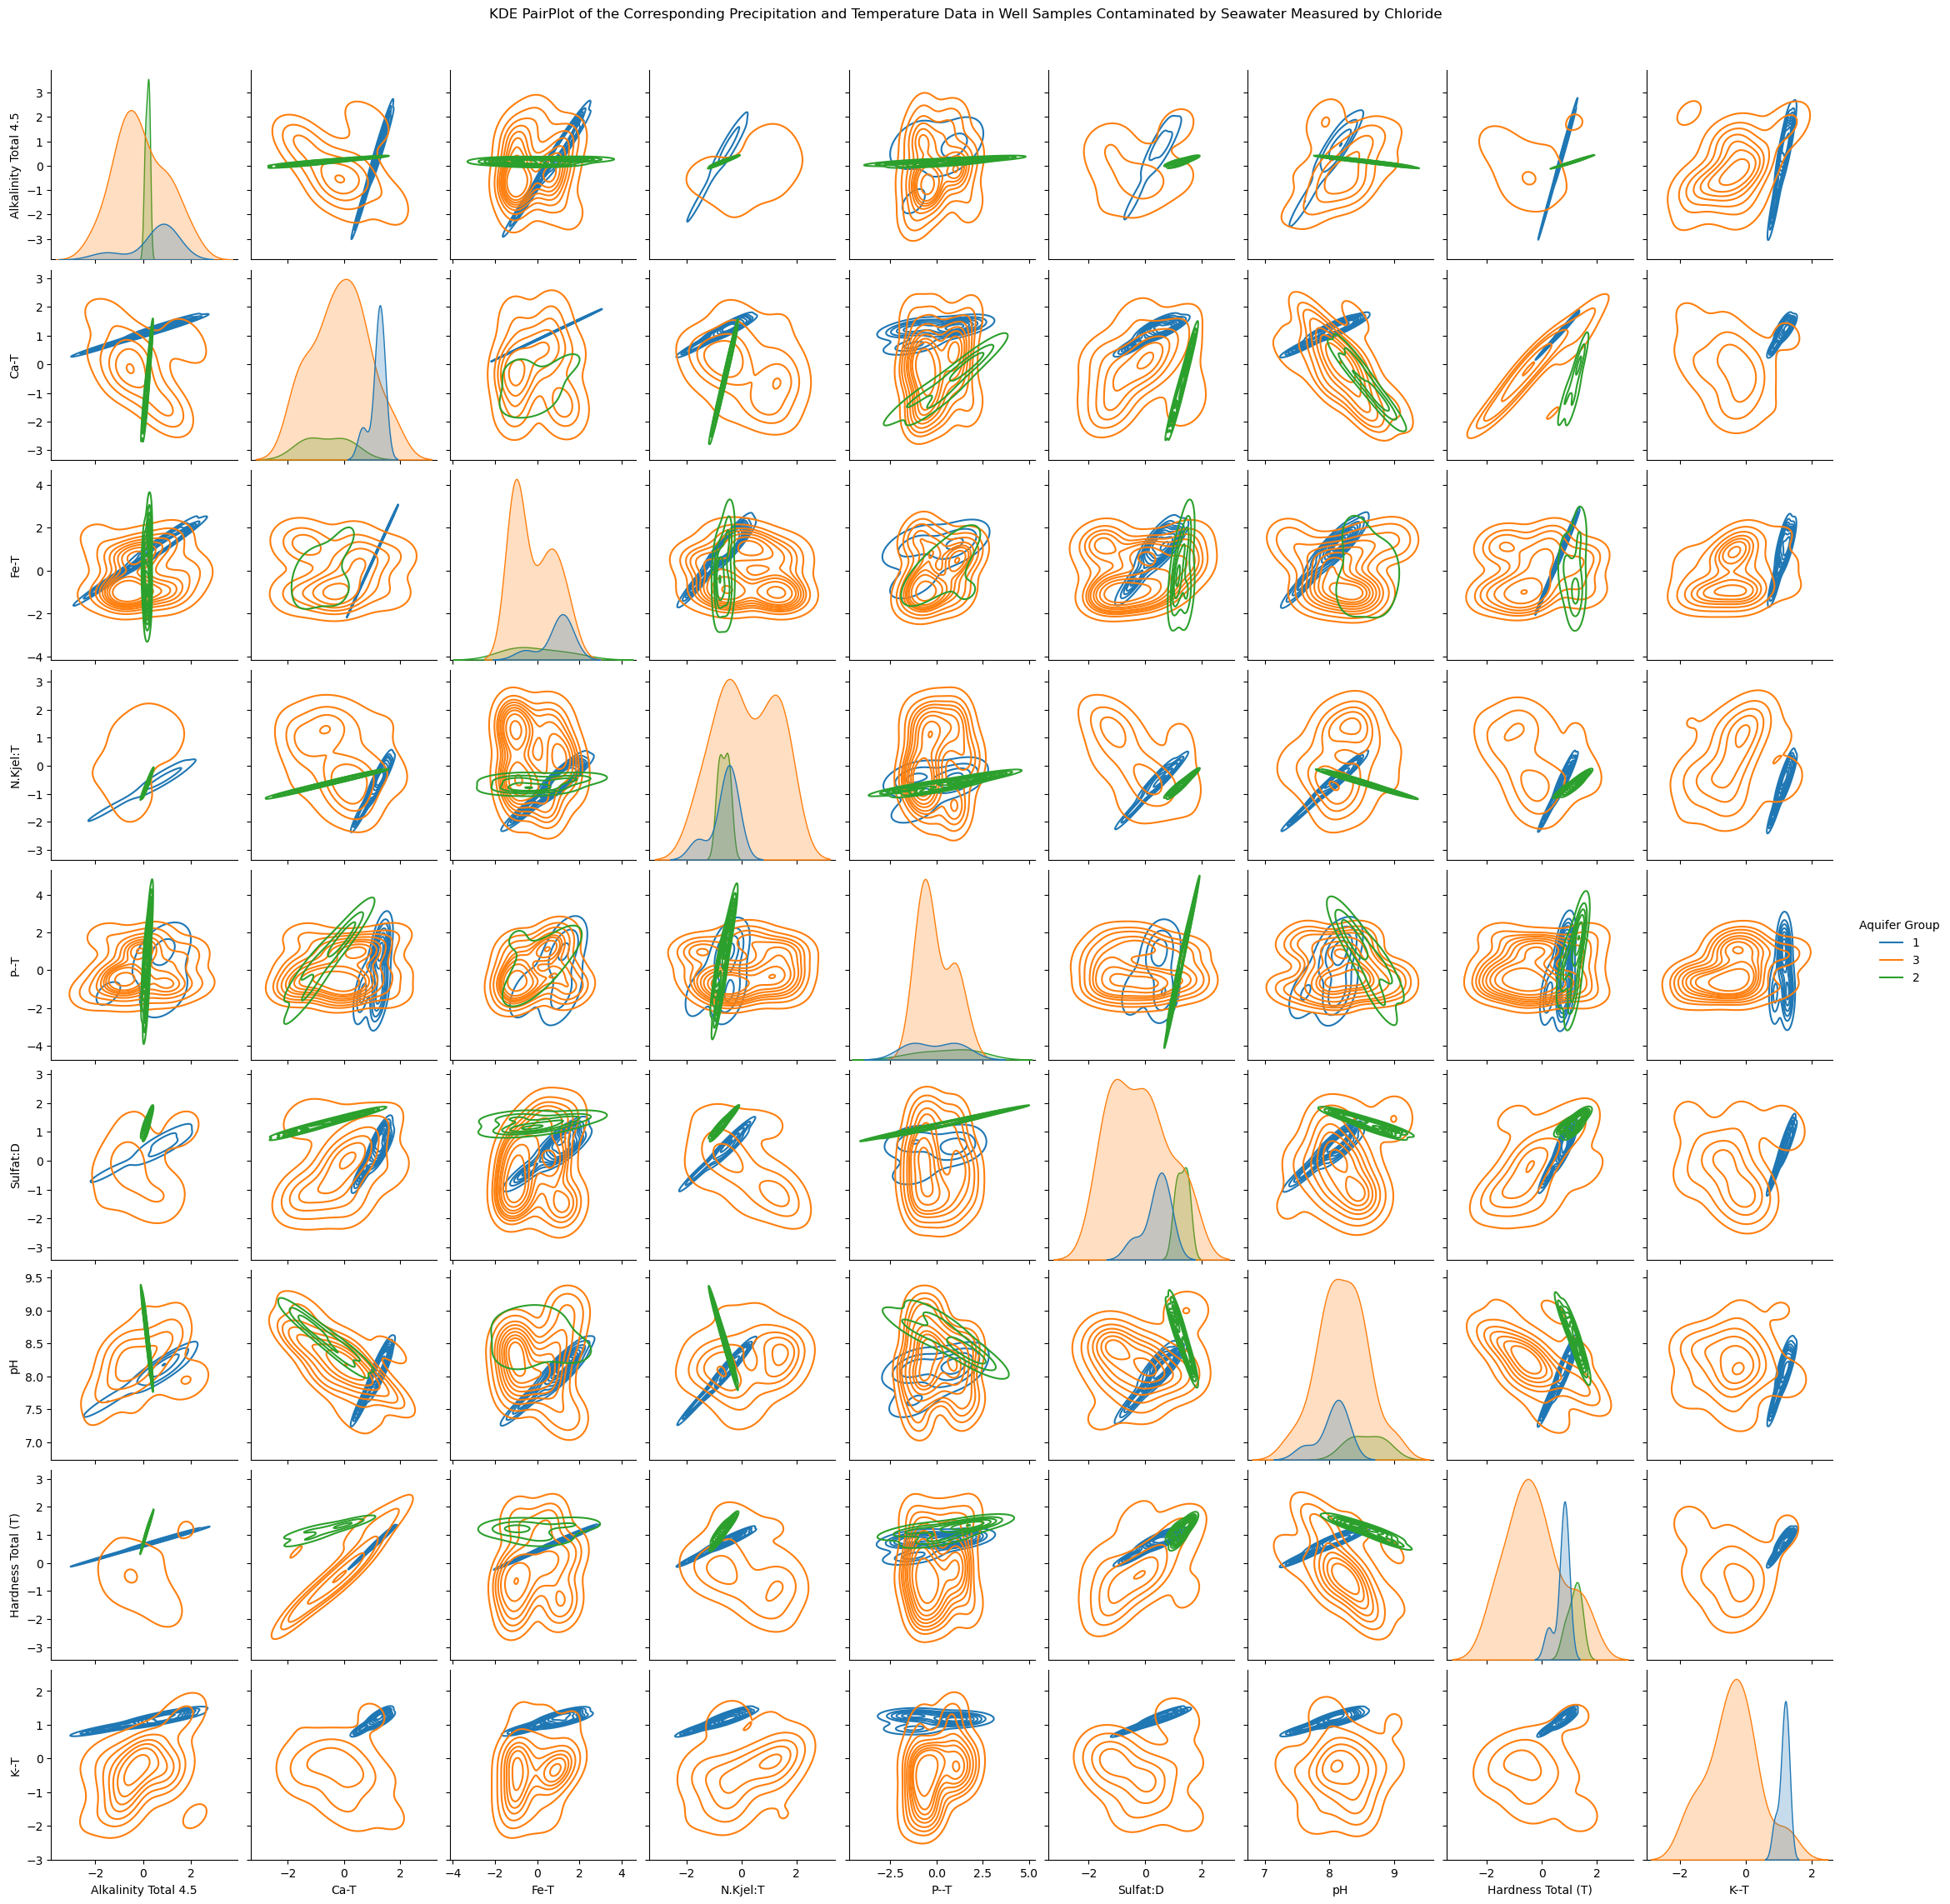

In [51]:
OthersDg= sns.pairplot(OthersD, hue="Aquifer Group")
OthersDg.fig.suptitle("PairPlot of Other Corresponding Concentrations in Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/pairplotOthersDSWIcl.png') # Save the first figure

OthersDh = sns.pairplot(OthersD, hue="Aquifer Group", kind="hist")
OthersDh.fig.suptitle("Histogram PairPlot of Other Corresponding Concentrations in Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/histplotOthersDSWIcl.png') 

Othersf = sns.pairplot(OthersD, hue="Aquifer Group", kind="kde")
Othersf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data in Well Samples Contaminated by Seawater Measured by Chloride", y=1.02)
plt.savefig('Figures/KDEplotOthersSWIcl.png') 

In [52]:
df_SWIcl.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [53]:
df_SWIcl.shape

(45, 24)

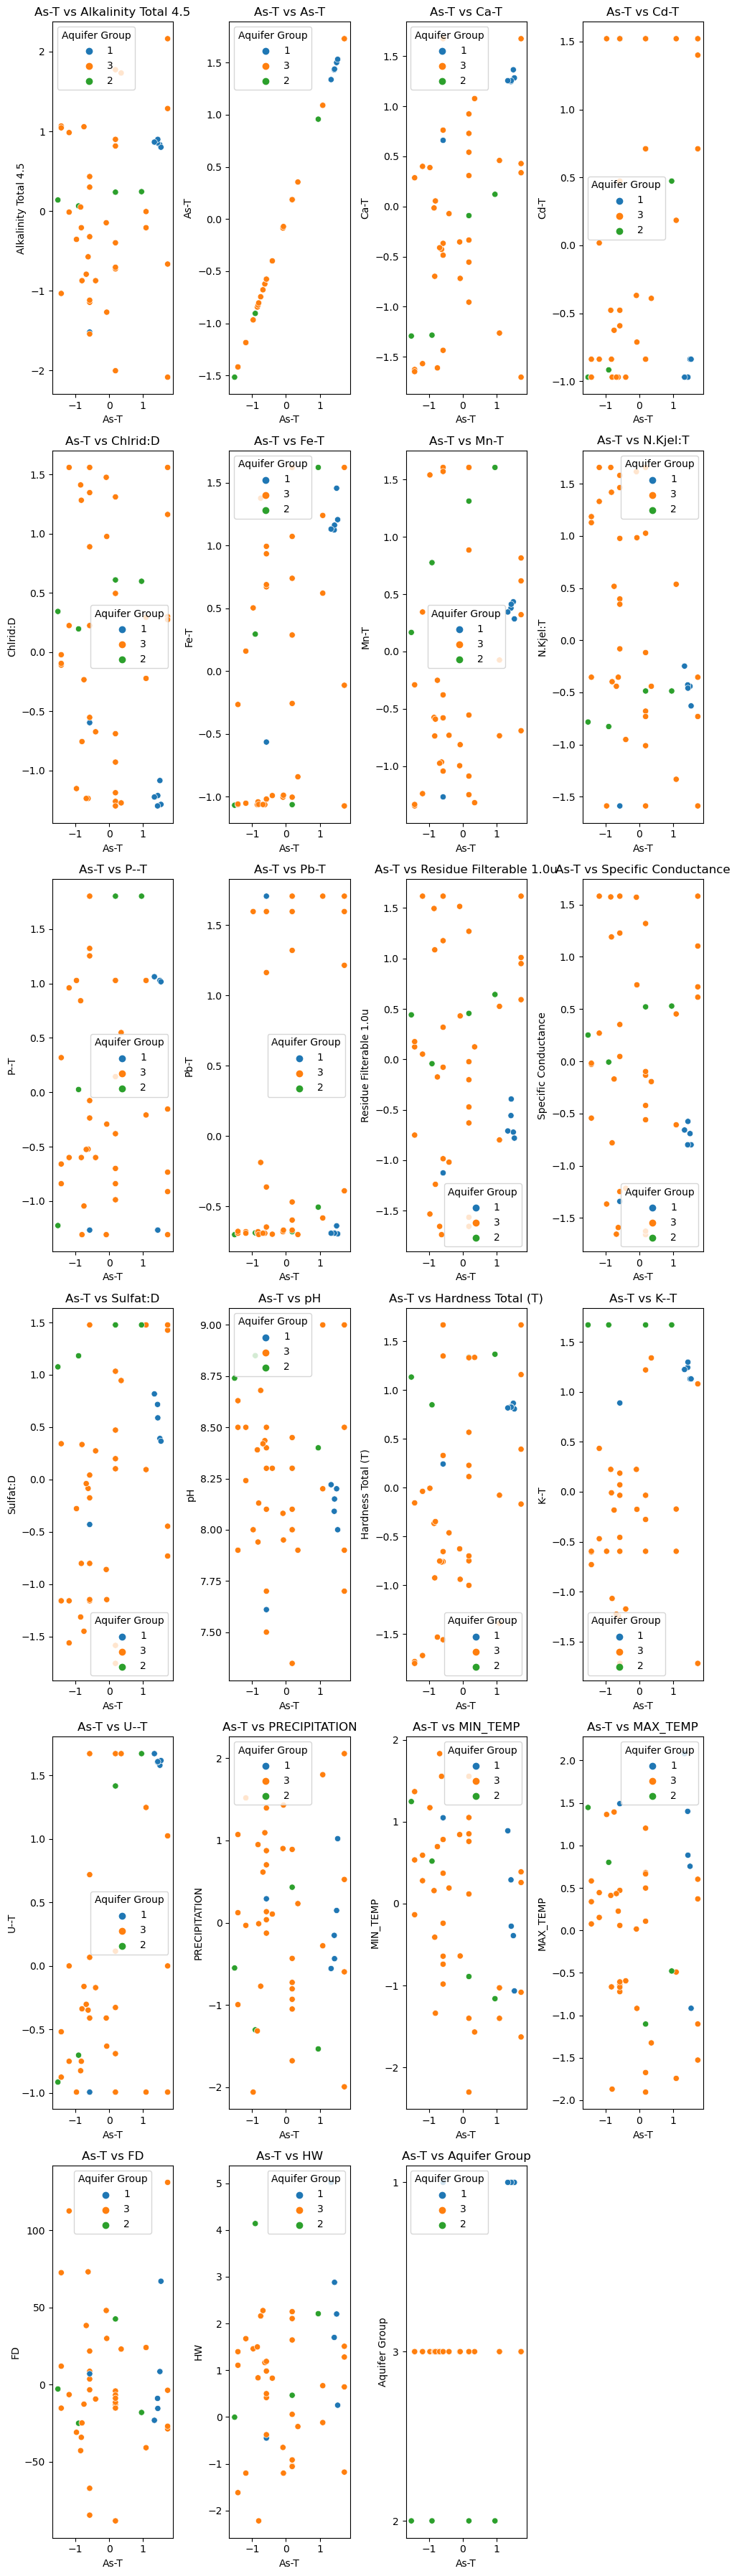

<Figure size 1000x800 with 0 Axes>

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_SWIcl is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIcl.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='As-T', y=pmetal, data=df_SWIcl, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'As-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/ASTSWIcl.png') 

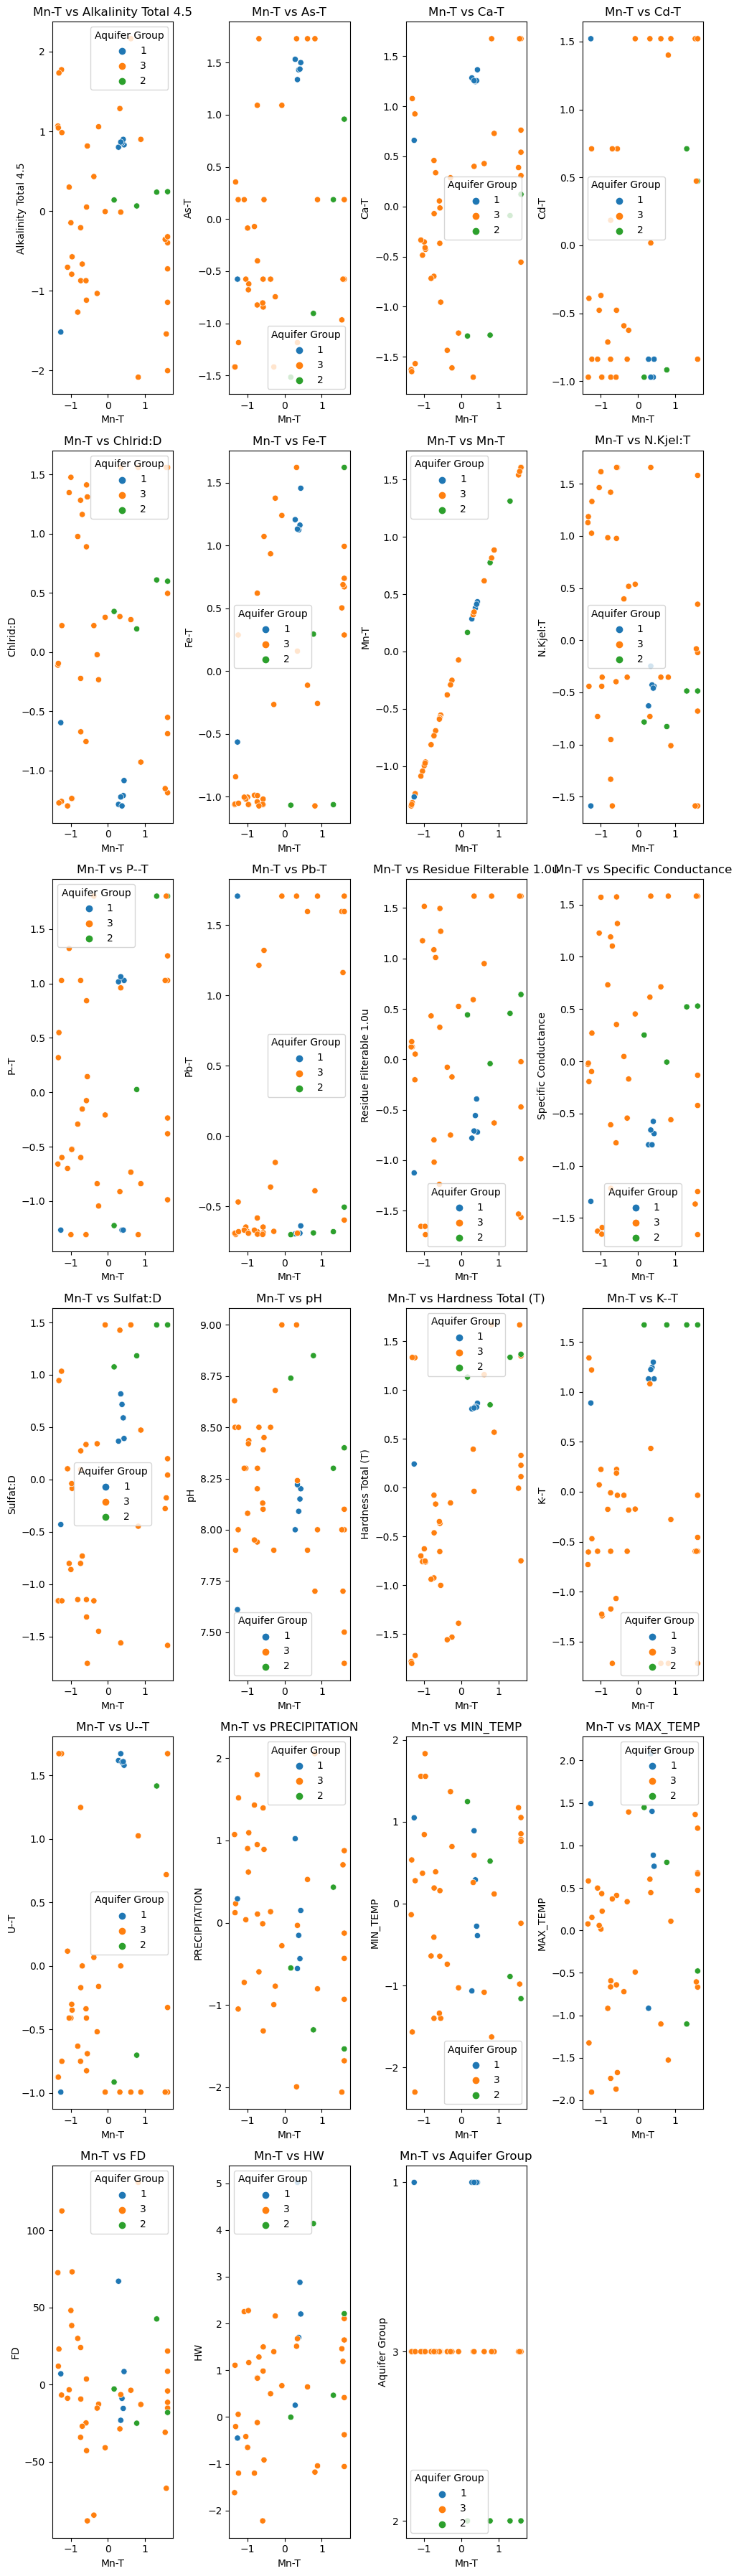

<Figure size 1000x800 with 0 Axes>

In [55]:
# Assuming df_SWIcl is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIcl.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Mn-T', y=pmetal, data=df_SWIcl, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Mn-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/MnTSWIcl.png') 

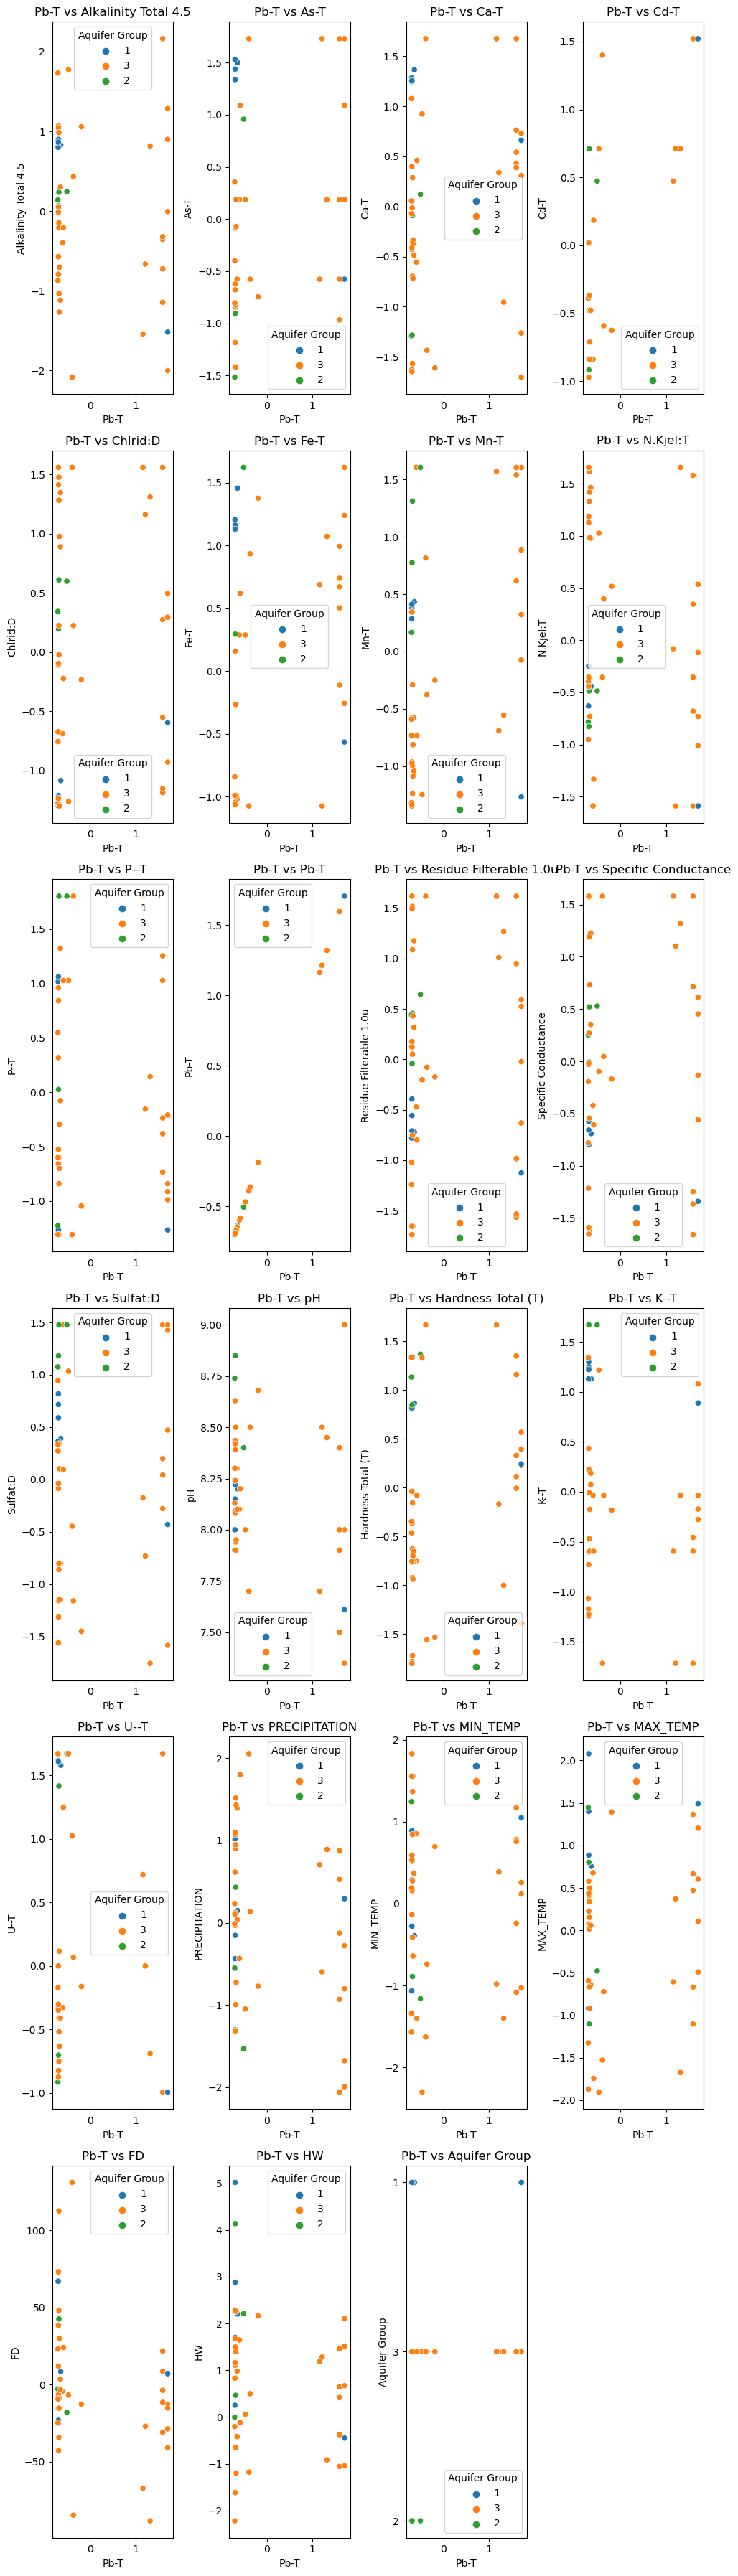

<Figure size 1000x800 with 0 Axes>

In [56]:
# Assuming df_SWIcl is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIcl.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Pb-T', y=pmetal, data=df_SWIcl, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Pb-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/PbTSWIcl.png') 

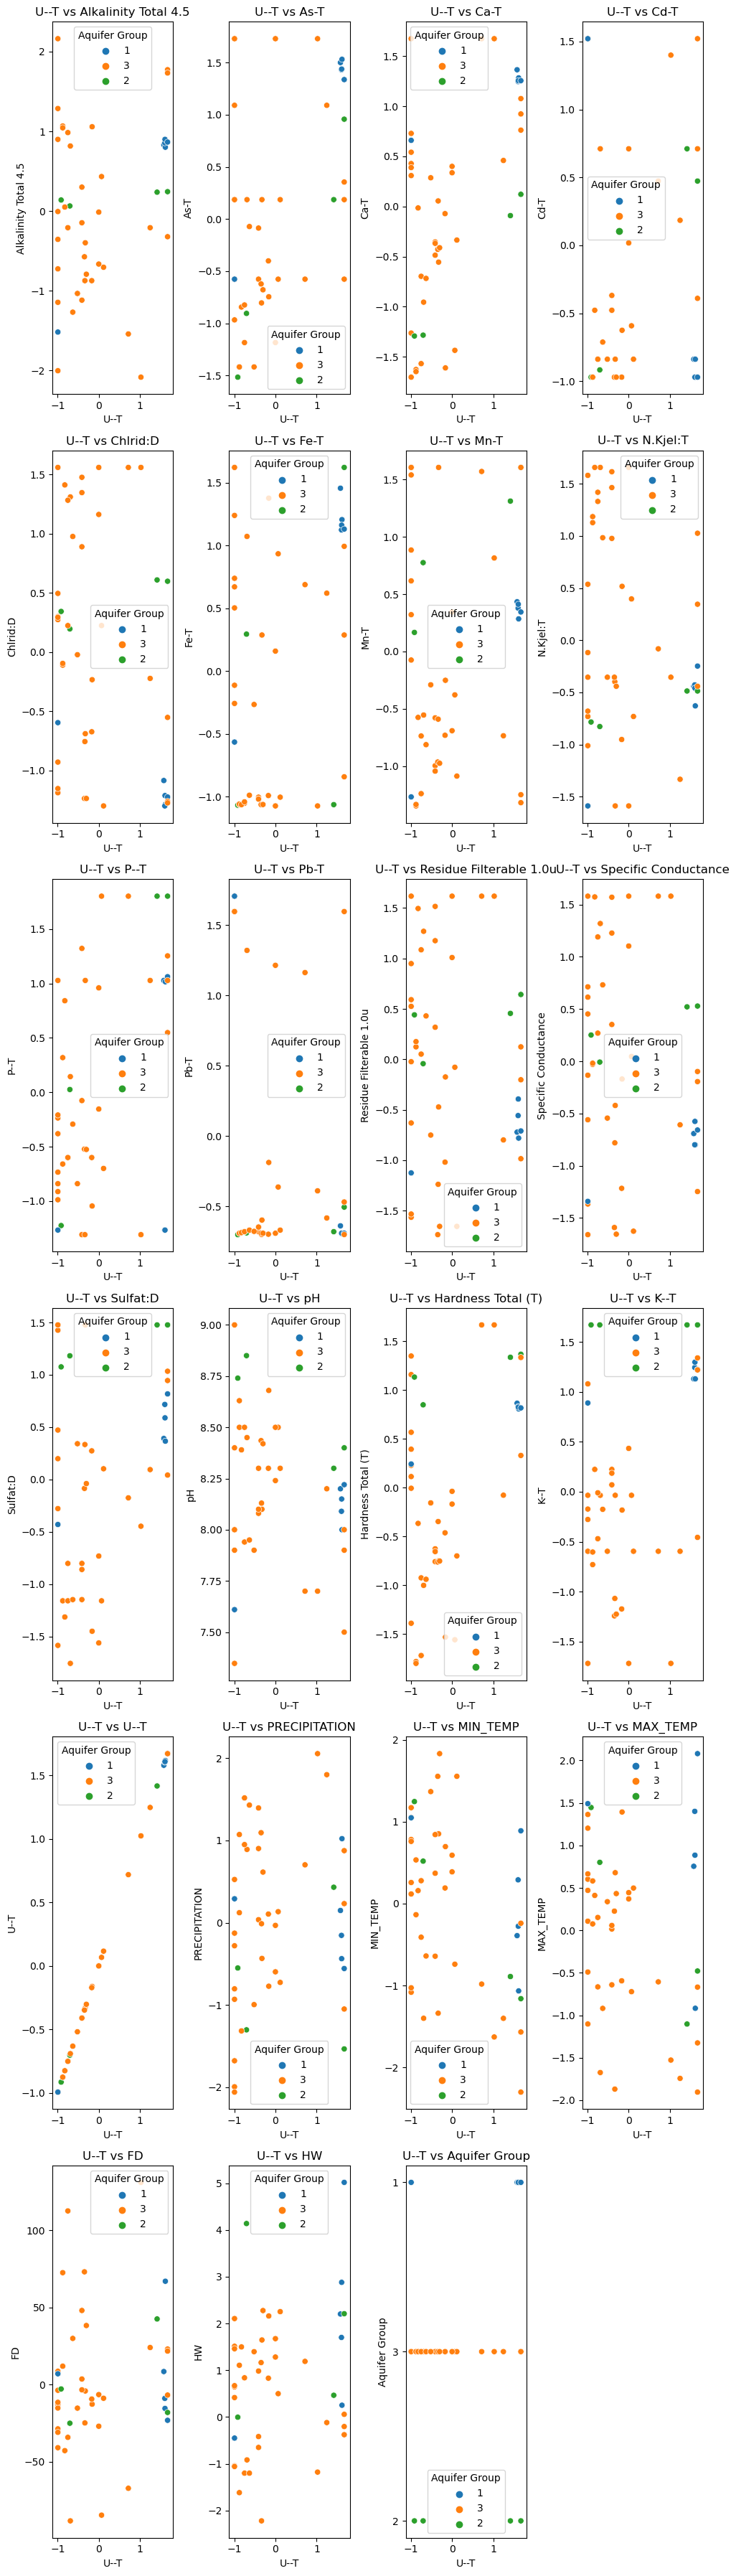

<Figure size 1000x800 with 0 Axes>

In [57]:
# Assuming df_SWIcl is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIcl.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='U--T', y=pmetal, data=df_SWIcl, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'U--T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/UTSWIcl.png') 

In [58]:
df_SWIcltime = Datawithtime[Datat['Chlrid:D'] > 150]
cleaned_dataset_array2 = replace_outliers_with_iqr(df_SWIcltime[numeric_cols1], 1.5)
df_SWIcltime[numeric_cols1] = cleaned_dataset_array2
#cleaned_dataset_array2a = replace_outliers_with_threshold(df_SWIcltime[numeric_cols], threshold_multiplier=3)
#cleaned_dataset2 = pd.DataFrame(cleaned_dataset_array2a, columns=numeric_cols, index=df_SWIcltime.index)
#df_SWIcltime[numeric_cols] = cleaned_dataset2

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_46720\1957153248.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWIcltime[numeric_cols1] = cleaned_dataset_array2


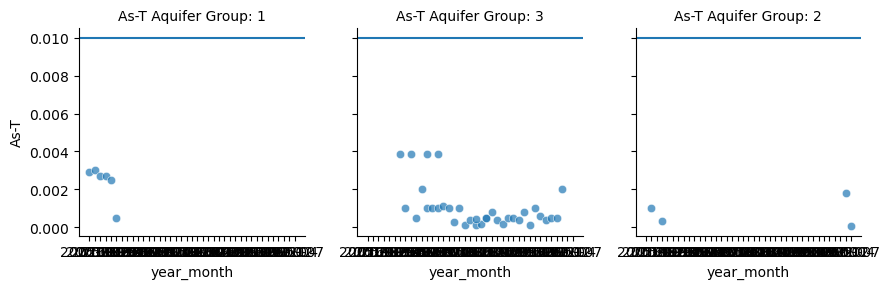

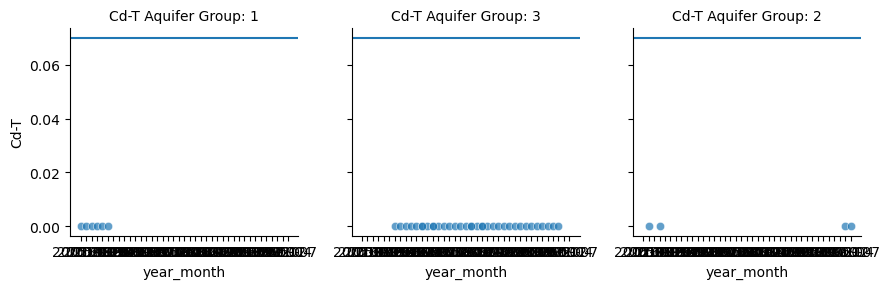

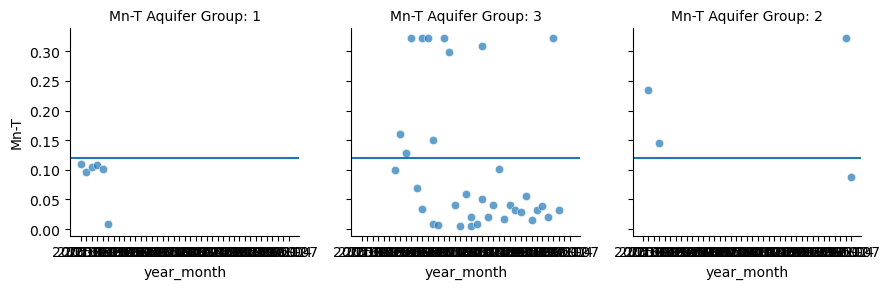

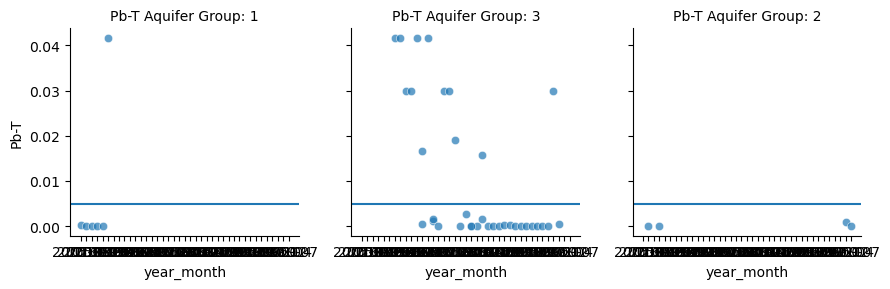

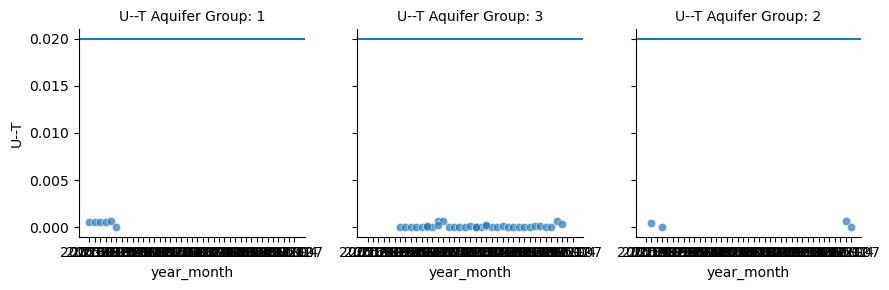

<Figure size 1000x800 with 0 Axes>

In [59]:
Total_Metals = df_SWIcltime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
plt.savefig('Figures/metalsoverCADdrinkingwaterSWIcl.png')

In [60]:
CANDMetalspre = df_SWIcltime[['OBSWELL', 'As-T', 'Mn-T', 'Pb-T', 'U--T']]
filtered_dfAs = CANDMetalspre[(CANDMetalspre['As-T'] >= 0.01)]
obs_well_valuesAs = filtered_dfAs['OBSWELL']
obs_well_valuesAs.shape

(0,)

In [61]:
filtered_dfMn = CANDMetalspre[(CANDMetalspre['Mn-T'] >= 0.12)]
obs_well_valuesMn = filtered_dfMn['OBSWELL']
obs_well_valuesMn.shape

(13,)

In [62]:
filtered_dfPb = CANDMetalspre[(CANDMetalspre['Pb-T'] >= 0.005)]
obs_well_valuesPb = filtered_dfPb['OBSWELL']
obs_well_valuesPb.shape

(13,)

In [63]:
filtered_dfU = CANDMetalspre[(CANDMetalspre['U--T'] >= 0.02)]
obs_well_valuesU = filtered_dfU['OBSWELL']
obs_well_valuesU.shape

(0,)

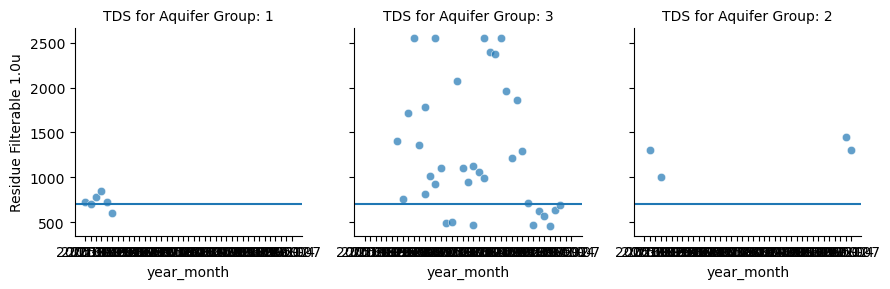

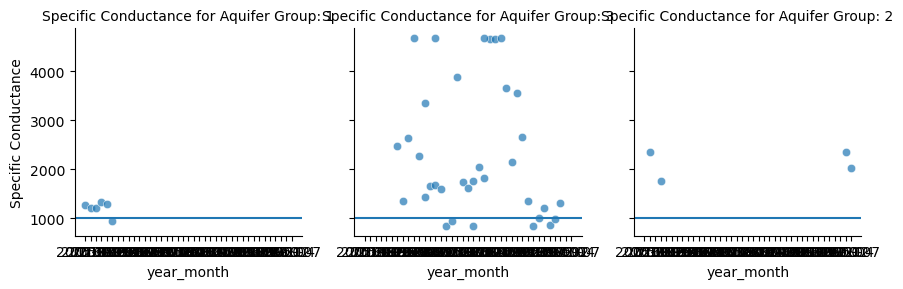

In [64]:
'''
Graphs of Saltwater intrusion
'''
SI_values = df_SWIcltime[['year_month', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D', 'Aquifer Group']]


TDS = sns.FacetGrid(SI_values, col="Aquifer Group")
TDS.map(sns.scatterplot, "year_month", "Residue Filterable 1.0u", alpha=.7)
TDS.map(lambda x, **kwargs: plt.axhline(y=700, **kwargs), "year_month")
TDS.set_titles("TDS for Aquifer Group: {col_name}")  # Setting title for each subplot

SC = sns.FacetGrid(SI_values, col="Aquifer Group")
SC.map(sns.scatterplot, "year_month", 'Specific Conductance', alpha=.7)
SC.map(lambda x, **kwargs: plt.axhline(y=1000, **kwargs), "year_month")
SC.set_titles("Specific Conductance for Aquifer Group: {col_name}")  # Setting title for each subplot
'''
Cld = sns.FacetGrid(SI_values, col="Aquifer Group")
Cld.map(sns.scatterplot, 'year_month', 'Chlrid:D', alpha=.7)
Cld.map(lambda x, **kwargs: plt.axhline(y=150, **kwargs), "year_month")
Cld.set_titles("Chloride for Aquifer Group: {col_name}")  # Setting title for each subplot
'''
plt.savefig('Figures/SIoverwellstimeSWIcl.png')

In [65]:
SWInow = df_SWIcltime[['OBSWELL', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D',]]

filtered_dTDS = SWInow[(SWInow['Residue Filterable 1.0u'] >= 750)]
obs_well_valuesTDS = filtered_dTDS['OBSWELL']
obs_well_valuesTDS.shape

(31,)

In [66]:
filtered_dSC = SWInow[(SWInow['Specific Conductance'] >= 1000)]
obs_well_valuesSC = filtered_dSC['OBSWELL']
obs_well_valuesSC.shape

(38,)

In [67]:
filtered_dC = SWInow[(SWInow['Chlrid:D'] >= 150)]
obs_well_valuesC = filtered_dC['OBSWELL']
obs_well_valuesC.shape

(45,)

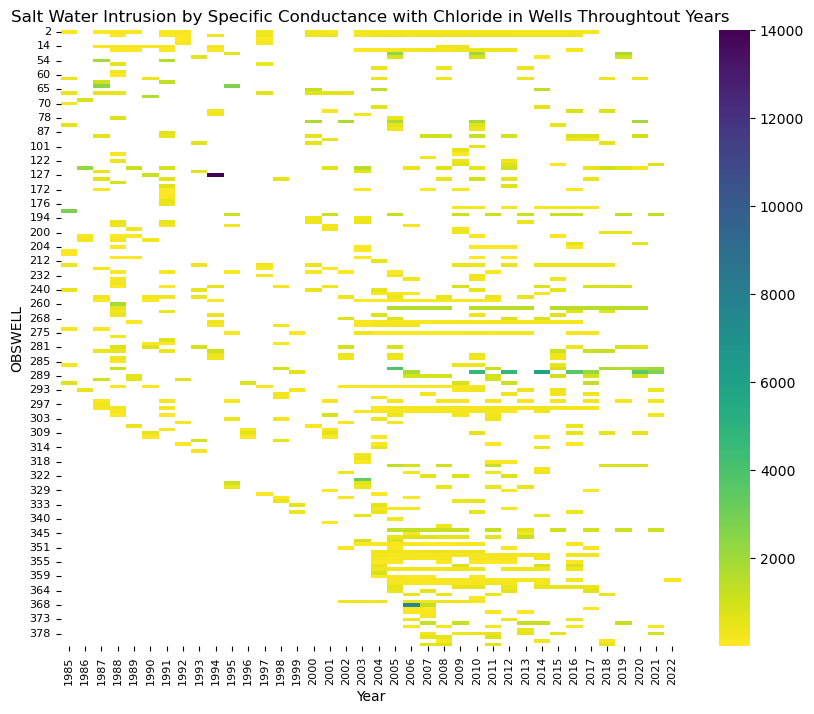

<Figure size 1000x800 with 0 Axes>

In [68]:
df_SWIcltime = Datawithtime.copy()  # create a copy of Datawithtime to avoid modifying the original DataFrame
df_SWIcltime['DATE'] = pd.to_datetime(df_SWIcltime['DATE'])  # convert 'DATE' column to datetime
df_SWIcltime['Year'] = df_SWIcltime['DATE'].dt.year  # extract year from 'DATE' column

SWIcl = df_SWIcltime.pivot_table(index="OBSWELL", columns="Year", values="Specific Conductance")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWIcl, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Specific Conductance with Chloride in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapSCSWIcl.png') 


In [69]:
'''
SWIcl = df_SWIcltime.pivot_table(index="OBSWELL", columns="Year", values="Chlrid:D")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWIcl, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Chloride in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapClSWIcl.png') 
'''

'\nSWIcl = df_SWIcltime.pivot_table(index="OBSWELL", columns="Year", values="Chlrid:D")\n\n# Create the heatmap\nplt.figure(figsize=(10,8))  # optionally set the figure size\nax = sns.heatmap(SWIcl, annot=False, cmap=\'viridis_r\')\n# Set the size of the x and y tick labels\nax.xaxis.set_tick_params(labelsize=8)\nax.yaxis.set_tick_params(labelsize=8)\nplt.title(\'Salt Water Intrusion by Chloride in Wells Throughtout Years\')  # add a title\nplt.show()\nplt.savefig(\'Figures/SWIheatmapClSWIcl.png\') \n'

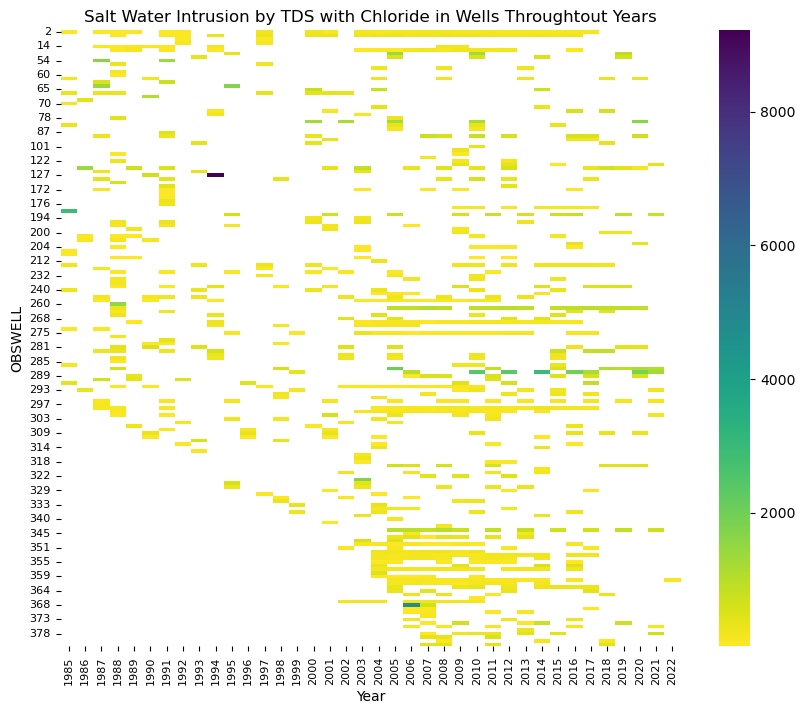

<Figure size 1000x800 with 0 Axes>

In [70]:
SWItds = df_SWIcltime.pivot_table(index="OBSWELL", columns="Year", values="Residue Filterable 1.0u")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWItds, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by TDS with Chloride in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapTDSSWIcl.png')